# Klasifikasi Kesegaran Daun Tanaman Kampus (Topik 2) — Modul Deep Learning (MobileNetV2) & Grad-CAM
**Mata Kuliah:** Pengolahan Citra Digital dan Visi Komputer (CIF61339) - Kelas A  
**Dosen Pengampu:** Yuita Arum Sari, S.Kom., M.Kom., Ph.D.  
**Fakultas Ilmu Komputer (FILKOM), Universitas Brawijaya**

**Penanggung Jawab Modul:**  
3. **Muzhaffar Ammar** - *Mahasiswa 3: Deep Learning (Transfer Learning MobileNetV2) & Visual Explainability (Grad-CAM)*

---
### Tujuan & Cakupan Notebook (Progress 2 — Inisiasi Baseline Deep Learning & Visual Explainability)
Notebook ini mengeksekusi tahapan *High-Level Vision* berbasis *Convolutional Neural Network* (CNN) dengan mengonsumsi langsung citra terproses ($619$ citra) dan indeks partisi anti-leakage `dataset_master_p2.csv` dari modul Mahasiswa 1 (`02_PCD_Augmentation_and_Split_P2.ipynb`), sekaligus menyiapkan perbandingan langsung dengan modul Mahasiswa 2 (`03_Feature_Extraction_and_ML_P2.ipynb` — Random Forest Tuned `92.72%` Macro-F1):
1. **Validasi GPU Colab & Muat `dataset_master_p2.csv`:** Memastikan akselerasi GPU aktif, memuat metadata $619$ citra ($127$ citra kamera asli + $492$ citra augmentasi seragam), serta memverifikasi ketersediaan kolom citra **Skenario B (`path_A0_raw`)**, **Skenario C2 (`path_C2_masked`)**, dan **Skenario C1** (jika tersedia).
2. **Arsitektur Transfer Learning MobileNetV2 (*Two-Stage Fine-Tuning*):**
   - Menggunakan *backbone* `MobileNetV2` (*pretrained* ImageNet, input $224 \times 224 \times 3$, normalisasi `preprocess_input` $[-1, 1]$) yang dirangkai secara *flat Functional Graph* dengan *Custom Classification Head* (`GlobalAveragePooling2D` $\rightarrow$ `BatchNormalization` $\rightarrow$ `Dropout(0.35)` $\rightarrow$ `Dense(128, relu)` $\rightarrow$ `Dropout(0.25)` $\rightarrow$ `Dense(3, softmax)`).
   - **Tahap 1 (*Feature Extraction / Warm-up Head*):** Membekukan seluruh bobot *backbone* ImageNet (`trainable=False`) dan melatih *classification head* (`lr=1e-3`).
   - **Tahap 2 (*Fine-Tuning Top Layers*):** Membuka 30 layer konvolusi teratas (`base_model.layers[-30:]`, dengan layer `BatchNormalization` tetap dibekukan agar statistik fitur ImageNet stabil) menggunakan *learning rate* rendah (`lr=1e-4`).
3. **Evaluasi 5-Fold Cross-Validation Anti-Leakage:**
   - Pada setiap *fold* $k \in \{0,1,2,3,4\}$, **Test Set** 100% murni citra kamera asli (`is_augmented == 0`) pada `fold == k` ($N_{test} = 127$ lintas 5 *fold*).
   - **Validation Set** untuk `EarlyStopping` dan `ReduceLROnPlateau` dipisahkan secara ketat berdasarkan `parent_id` menggunakan `StratifiedGroupKFold` dan disaring hanya pada citra asli (`is_augmented == 0`), sehingga tidak ada kebocoran data augmentasi maupun kebocoran ke *Test Set*.
4. **Artefak Visual Presentasi Progress 2 & Persiapan Progress 3:**
   - **`P2_Slide12_MobileNetV2_Training_Curves.png`**: Kurva konvergensi *Training vs Validation Accuracy & Loss* (Tahap 1 & Tahap 2).
   - **`P2_Slide12_MobileNetV2_Confusion_Matrix.png`**: Matriks konfusi $3 \times 3$ (*Out-of-Fold* pada $127$ citra asli) membandingkan **Skenario B (Raw)** vs **Skenario C2 (PCD Masked)**.
   - **`P2_Slide12_GradCAM_Preview.png`**: Peta aktivasi spasial **Grad-CAM** pada layer `out_relu` untuk membuktikan fokus atensi jaringan CNN pada area klorosis/nekrosis daun.
   - **`P2_Tabel5_Evaluasi_MobileNetV2.csv`**, **`oof_dl_mobilenetv2_p2.csv`**, dan model tersimpan **`.keras`**.

## 0. Setup Lingkungan GPU, Reproducibility Seed, & Muat `dataset_master_p2.csv`
**Tujuan:**
- Mengaktifkan Google Drive dan memastikan direktori proyek `Dataset_P2_Processed` dapat diakses.
- Memeriksa ketersediaan akselerator **GPU** pada Google Colab (disarankan mengaktifkan menu `Runtime` $\rightarrow$ `Change runtime type` $\rightarrow$ `T4 GPU` agar pelatihan 5-Fold selesai dalam ~2–3 menit).
- Mengunci *random seed* (`SEED = 42`) pada Python, NumPy, dan TensorFlow demi keterulangan eksperimen (*reproducibility*).

In [1]:
import os
import random
import warnings
warnings.filterwarnings('ignore')

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from google.colab import drive

# 1. Kunci Random Seed untuk Reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. Cek Ketersediaan GPU
gpus = tf.config.list_physical_devices('GPU')
print(f'TensorFlow Version : {tf.__version__}')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f'GPU Terdeteksi     : {gpus[0].name} (Akselerasi Aktif)')
else:
    print('PERINGATAN: GPU tidak aktif! Aktifkan T4 GPU di Runtime -> Change runtime type agar training cepat.')

# 3. Hubungkan Google Drive & Muat dataset_master_p2.csv
drive.mount('/content/drive')

OUT_BASE = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2'
MODEL_DIR = os.path.join(OUT_BASE, 'Models_DL_MobileNetV2')
os.makedirs(MODEL_DIR, exist_ok=True)

csv_master_path = os.path.join(OUT_BASE, 'dataset_master_p2.csv')
if not os.path.exists(csv_master_path):
    raise FileNotFoundError(
        f"File '{csv_master_path}' tidak ditemukan. "
        "Pastikan 02_PCD_Augmentation_and_Split_P2.ipynb sudah dijalankan."
    )

df_master_p2 = pd.read_csv(csv_master_path)
print(f'\nBerhasil memuat dataset_master_p2.csv: {len(df_master_p2)} citra')
print('Kolom tersedia:', list(df_master_p2.columns))
print('\nDistribusi Kelas vs Status Augmentasi:')
print(pd.crosstab(df_master_p2['label'], df_master_p2['is_augmented'], margins=True))

TensorFlow Version : 2.21.0
GPU Terdeteksi     : /physical_device:GPU:0 (Akselerasi Aktif)
Mounted at /content/drive

Berhasil memuat dataset_master_p2.csv: 619 citra
Kolom tersedia: ['sample_id', 'parent_id', 'original_filename', 'label', 'sesi', 'fold', 'is_augmented', 'aug_type', 'gamma_used', 'resolusi', 'path_A0_raw', 'path_C1_nomask', 'path_C2_masked', 'path_mask']

Distribusi Kelas vs Status Augmentasi:
is_augmented    0    1  All
label                      
Kering         35  175  210
Menguning      51  153  204
Sehat          41  164  205
All           127  492  619


## 1. Pemuatan & Pra-pemrosesan Tensor Citra ($224 \times 224 \times 3$)
**Tujuan:**
- Mendefinisikan pemetaan kelas standar yang konsisten di seluruh modul proyek: `{'Sehat': 0, 'Menguning': 1, 'Kering': 2}`.
- Memuat seluruh $619$ citra untuk masing-masing skenario input ke dalam memori RAM (ukuran total hanya ~370 MB untuk $619 \times 224 \times 224 \times 3$ `float32`) sehingga proses pelatihan 5-Fold CV berjalan sangat cepat tanpa *bottleneck* pembacaan disk Google Drive di setiap *epoch*.
- Menerapkan konversi ruang warna `BGR -> RGB` (karena `cv2.imread` membaca dalam urutan BGR sedangkan bobot *pretrained* ImageNet pada `MobileNetV2` dilatih pada urutan RGB) dan normalisasi `preprocess_input` ke rentang $[-1, 1]$.

In [2]:
CLASS_NAMES = ['Sehat', 'Menguning', 'Kering']
LABEL_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IDX_TO_LABEL = {idx: name for idx, name in enumerate(CLASS_NAMES)}
IMG_SIZE = (224, 224)

df_master_p2['label_idx'] = df_master_p2['label'].map(LABEL_TO_IDX)
assert df_master_p2['label_idx'].isnull().sum() == 0, 'Terdapat label tidak dikenal pada CSV!'

# Deteksi otomatis kolom skenario citra yang tersedia pada dataset_master_p2.csv
SCENARIO_PATHS = {
    'B: Raw Image (A0) + MobileNetV2': 'path_A0_raw',
    'C2: PCD Masked (C2) + MobileNetV2': 'path_C2_masked'
}
# Jika kolom Skenario C1 (PCD tanpa masking) tersedia di CSV, otomatis ikut dievaluasi
c1_candidates = [c for c in df_master_p2.columns if 'C1' in c and 'path' in c.lower()]
if c1_candidates:
    SCENARIO_PATHS['C1: PCD Unmasked (C1) + MobileNetV2'] = c1_candidates[0]

print('Skenario eksperimen Deep Learning yang akan dievaluasi:')
for sc_name, col_name in SCENARIO_PATHS.items():
    print(f' - {sc_name} -> kolom [{col_name}]')

def preload_images_to_ram(df, path_col, img_size=(224, 224)):
    """Memuat seluruh citra dari path_col ke array NumPy RGB ter-preprocess [-1, 1]."""
    n = len(df)
    X_arr = np.zeros((n, img_size[0], img_size[1], 3), dtype=np.float32)
    missing_count = 0
    for i, img_path in enumerate(tqdm(df[path_col].values, desc=f'Loading {path_col}')):
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            missing_count += 1
            continue
        if (img_bgr.shape[1], img_bgr.shape[0]) != img_size:
            img_bgr = cv2.resize(img_bgr, img_size, interpolation=cv2.INTER_AREA)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).astype(np.float32)
        X_arr[i] = preprocess_input(img_rgb)
    if missing_count > 0:
        raise FileNotFoundError(f'Ditemukan {missing_count} file citra hilang pada kolom {path_col}!')
    return X_arr

X_DATA_DICT = {}
for sc_name, col_name in SCENARIO_PATHS.items():
    X_DATA_DICT[sc_name] = preload_images_to_ram(df_master_p2, col_name, IMG_SIZE)

y_all = df_master_p2['label_idx'].values
print(f'\nSelesai memuat tensor citra! Bentuk array per skenario: {X_DATA_DICT[list(SCENARIO_PATHS.keys())[0]].shape}')

Skenario eksperimen Deep Learning yang akan dievaluasi:
 - B: Raw Image (A0) + MobileNetV2 -> kolom [path_A0_raw]
 - C2: PCD Masked (C2) + MobileNetV2 -> kolom [path_C2_masked]
 - C1: PCD Unmasked (C1) + MobileNetV2 -> kolom [path_C1_nomask]


Loading path_C1_nomask: 100%|██████████| 619/619 [07:58<00:00,  1.29it/s]


Selesai memuat tensor citra! Bentuk array per skenario: (619, 224, 224, 3)


## 2. Definisi Arsitektur Transfer Learning MobileNetV2 & Strategi Pelatihan 2 Tahap
**Rasional Desain Arsitektur & Pelatihan:**
1. **Mengapa MobileNetV2?** Dengan ukuran dataset primer $N = 127$ citra asli ($N = 619$ pasca-augmentasi), arsitektur CNN yang terlalu dalam (seperti ResNet152 atau VGG19 dengan >140 juta parameter) sangat rentan mengalami *overfitting*. **MobileNetV2** memanfaatkan blok *Inverted Residuals* dan *Depthwise Separable Convolutions* (~2,26 juta parameter *backbone*), sehingga efisien secara komputasi, cepat dikonvergensi, dan sangat sesuai untuk potensi *deployment* perangkat *mobile*/edge pada tahapan lanjutan.
2. **Flat Functional Graph (Kompatibilitas Keras 3 & Grad-CAM):** *Classification head* disambungkan langsung ke tensor keluaran `base_model.output` (`out_relu`, dimensi $7 \times 7 \times 1280$) dalam satu grafik `tf.keras.Model` tunggal. Hal ini menjamin ekstraksi gradien spasial **Grad-CAM** berjalan mulus tanpa kendala pemutusan grafik antar-submodel.
3. **Two-Stage Fine-Tuning:**
   - **Stage 1 (Warm-up Head, 12 Epoch, `lr=1e-3`):** Seluruh layer *backbone* ImageNet dibekukan agar gradien acak pada *classifier* baru tidak merusak filter ekstraksi fitur visual yang sudah terlatih.
   - **Stage 2 (Fine-Tuning Top-30 Layers, 18 Epoch, `lr=1e-4`):** Membuka 30 layer teratas MobileNetV2 untuk mengadaptasi fitur tingkat tinggi (*leaf venation*, *chlorosis spots*, *necrotic edges*), sambil mempertahankan seluruh layer `BatchNormalization` dalam kondisi `trainable=False` agar *running mean/variance* ImageNet tidak terdistorsi oleh *batch size* kecil ($B = 16$).
4. **Protokol Anti-Leakage Penuh:** Pada setiap *fold* $k$, data pelatihan (`fold != k`) dipisah lagi menggunakan `StratifiedGroupKFold(n_splits=4, groups=parent_id)` menjadi `train_sub` dan `val_sub` (khusus citra asli `is_augmented == 0`) untuk memandu `EarlyStopping` dan `ReduceLROnPlateau`. **Test Fold $k$ (`is_augmented == 0`) sama sekali tidak pernah dilihat model selama proses pelatihan maupun pemilihan *checkpoint* terbaik.**

In [3]:
def build_mobilenetv2_classifier(num_classes=3, input_shape=(224, 224, 3), dropout_head=0.35):
    """
    Membangun arsitektur MobileNetV2 Transfer Learning dalam satu Functional Graph tunggal
    agar siap untuk Two-Stage Fine-Tuning dan Grad-CAM.
    """
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    # Stage 1: Bekukan seluruh layer backbone
    base_model.trainable = False

    x = base_model.output
    x = layers.GlobalAveragePooling2D(name='global_avg_pool')(x)
    x = layers.BatchNormalization(name='head_bn')(x)
    x = layers.Dropout(dropout_head, name='head_dropout_1')(x)
    x = layers.Dense(128, activation='relu', name='head_dense_128')(x)
    x = layers.Dropout(0.25, name='head_dropout_2')(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = models.Model(inputs=base_model.input, outputs=outputs, name='MobileNetV2_LeafFreshness')
    return model, base_model

def unfreeze_top_layers(base_model, fine_tune_from=-30):
    """
    Membuka layer teratas backbone untuk Stage 2 Fine-Tuning,
    namun menjaga seluruh layer BatchNormalization tetap frozen.
    """
    base_model.trainable = True
    for layer in base_model.layers[:fine_tune_from]:
        layer.trainable = False
    for layer in base_model.layers[fine_tune_from:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

def train_and_evaluate_5fold_dl(X_all, df_meta, scenario_tag, save_models=True, epochs_stage1=12, epochs_stage2=18, batch_size=16):
    """
    Menjalankan evaluasi 5-Fold Cross-Validation Anti-Leakage untuk MobileNetV2.
    - Test Fold k  : HANYA citra asli (is_augmented == 0) pada fold == k
    - Val Split    : HANYA citra asli (is_augmented == 0) dari 1 grup parent_id di luar train_sub
    - Train Split  : Citra asli + augmentasi pada sisa grup parent_id (fold != k)
    """
    fold_accs, fold_precs, fold_recs, fold_f1s = [], [], [], []
    y_true_oof, y_pred_oof, y_prob_oof, sample_ids_oof, sesi_oof = [], [], [], [], []
    history_records = {}
    best_fold_idx = 0
    best_fold_f1 = -1.0
    best_model_path = None

    for k in range(5):
        print(f'\n--- [{scenario_tag}] Fold {k+1}/5 ---')
        dev_mask = (df_meta['fold'] != k).values
        test_mask = ((df_meta['fold'] == k) & (df_meta['is_augmented'] == 0)).values

        df_dev = df_meta[dev_mask].reset_index(drop=True)
        X_dev = X_all[dev_mask]
        y_dev = df_dev['label_idx'].values

        # Pisahkan val_sub berbasis parent_id agar tidak ada kebocoran ke train_sub
        sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + k)
        sub_tr_idx, sub_va_idx = next(sgkf.split(X_dev, y_dev, groups=df_dev['parent_id'].values))

        # Validation set disaring hanya citra asli agar EarlyStopping objektif
        orig_va_filter = (df_dev.iloc[sub_va_idx]['is_augmented'] == 0).values
        final_va_idx = sub_va_idx[orig_va_filter]

        X_train, y_train = X_dev[sub_tr_idx], y_dev[sub_tr_idx]
        X_val, y_val     = X_dev[final_va_idx], y_dev[final_va_idx]
        X_test, y_test   = X_all[test_mask], df_meta[test_mask]['label_idx'].values

        # Hitung class_weight seimbang pada X_train
        classes_unique = np.unique(y_train)
        cw_vals = compute_class_weight(class_weight='balanced', classes=classes_unique, y=y_train)
        class_weight_dict = {int(c): float(w) for c, w in zip(classes_unique, cw_vals)}

        model, base_model = build_mobilenetv2_classifier(num_classes=len(CLASS_NAMES), input_shape=(224, 224, 3))

        # STAGE 1: Feature Extraction (Head Warm-up)
        model.compile(
            optimizer=optimizers.Adam(learning_rate=1e-3),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
        cb_stage1 = [
            callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=0)
        ]
        hist1 = model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=epochs_stage1,
            batch_size=batch_size,
            class_weight=class_weight_dict,
            callbacks=cb_stage1,
            verbose=0
        )

        # STAGE 2: Fine-Tuning Top-30 Layers
        unfreeze_top_layers(base_model, fine_tune_from=-30)
        model.compile(
            optimizer=optimizers.Adam(learning_rate=1e-4),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
        cb_stage2 = [
            callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=0),
            callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=0)
        ]
        hist2 = model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=epochs_stage2,
            batch_size=batch_size,
            class_weight=class_weight_dict,
            callbacks=cb_stage2,
            verbose=0
        )

        # Evaluasi pada Test Set murni citra asli (fold == k)
        y_prob = model.predict(X_test, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)

        acc  = accuracy_score(y_test, y_pred) * 100
        prec = precision_score(y_test, y_pred, average='macro', zero_division=0) * 100
        rec  = recall_score(y_test, y_pred, average='macro', zero_division=0) * 100
        f1   = f1_score(y_test, y_pred, average='macro', zero_division=0) * 100

        fold_accs.append(acc)
        fold_precs.append(prec)
        fold_recs.append(rec)
        fold_f1s.append(f1)

        y_true_oof.extend(y_test)
        y_pred_oof.extend(y_pred)
        y_prob_oof.extend(y_prob)
        sample_ids_oof.extend(df_meta[test_mask]['sample_id'].values)
        sesi_oof.extend(df_meta[test_mask]['sesi'].values)

        history_records[k] = {
            'stage1': hist1.history,
            'stage2': hist2.history
        }

        print(f'Fold {k+1} Test (N={len(y_test)} asli) -> Accuracy: {acc:.2f}% | Macro-F1: {f1:.2f}%')

        if f1 > best_fold_f1:
            best_fold_f1 = f1
            best_fold_idx = k
            if save_models:
                safe_tag = scenario_tag.split(':')[0].strip()
                best_model_path = os.path.join(MODEL_DIR, f'best_mobilenetv2_{safe_tag}_fold{k}.keras')
                model.save(best_model_path)

    summary_dict = {
        'Skenario Eksperimen': scenario_tag,
        'Arsitektur': 'MobileNetV2 (Two-Stage FT)',
        'Accuracy (%)': f'{np.mean(fold_accs):.2f} ± {np.std(fold_accs):.2f}',
        'Macro-Precision (%)': f'{np.mean(fold_precs):.2f} ± {np.std(fold_precs):.2f}',
        'Macro-Recall (%)': f'{np.mean(fold_recs):.2f} ± {np.std(fold_recs):.2f}',
        'Macro-F1 (%)': f'{np.mean(fold_f1s):.2f} ± {np.std(fold_f1s):.2f}',
        '_f1_mean': float(np.mean(fold_f1s)),
        '_acc_mean': float(np.mean(fold_accs))
    }

    df_oof = pd.DataFrame({
        'sample_id': sample_ids_oof,
        'sesi': sesi_oof,
        'y_true_idx': y_true_oof,
        'y_pred_idx': y_pred_oof,
        'y_true': [IDX_TO_LABEL[i] for i in y_true_oof],
        'y_pred': [IDX_TO_LABEL[i] for i in y_pred_oof],
        'prob_Sehat': np.array(y_prob_oof)[:, 0],
        'prob_Menguning': np.array(y_prob_oof)[:, 1],
        'prob_Kering': np.array(y_prob_oof)[:, 2],
        'scenario': scenario_tag
    })

    return summary_dict, df_oof, history_records, best_fold_idx, best_model_path

print('Fungsi arsitektur MobileNetV2 & protokol evaluasi 5-Fold Anti-Leakage siap dijalankan.')

Fungsi arsitektur MobileNetV2 & protokol evaluasi 5-Fold Anti-Leakage siap dijalankan.


## 3. Eksekusi Eksperimen Komparatif Deep Learning (Skenario B vs C1 vs C2)
**Tujuan:**
- Menjalankan pelatihan dan evaluasi 5-Fold Cross-Validation Anti-Leakage pada ketiga skenario input citra:
  1. **Skenario B (`path_A0_raw` + MobileNetV2):** Citra mentah $224 \times 224$ tanpa *preprocessing* PCD (masih memuat latar belakang kertas putih).
  2. **Skenario C1 (`path_C1_nomask` + MobileNetV2):** Citra terproses PCD (*Adaptive Gamma $L^*$*, *Bilateral Filter*, *CLAHE*) **tanpa** penghapusan latar (*unmasked*).
  3. **Skenario C2 (`path_C2_masked` + MobileNetV2):** Citra terproses PCD **dengan** segmentasi & masking ROI daun (*background* dihapus).
- Menyimpan tabel hasil **`P2_Tabel5_Evaluasi_MobileNetV2.csv`** dan prediksi *Out-of-Fold* **`oof_dl_mobilenetv2_p2.csv`** ke Google Drive.

In [4]:
dl_summaries = []
dl_oof_dict = {}
dl_histories = {}
dl_best_folds = {}
dl_best_model_paths = {}

for sc_name, X_tensor in X_DATA_DICT.items():
    print('\n' + '=' * 85)
    print(f'MEMULAI PELATIHAN & EVALUASI 5-FOLD CV: {sc_name}')
    print('=' * 85)
    summary, df_oof, hist_rec, best_k, best_path = train_and_evaluate_5fold_dl(
        X_all=X_tensor,
        df_meta=df_master_p2,
        scenario_tag=sc_name,
        save_models=True,
        epochs_stage1=12,
        epochs_stage2=18,
        batch_size=16
    )
    dl_summaries.append(summary)
    dl_oof_dict[sc_name] = df_oof
    dl_histories[sc_name] = hist_rec
    dl_best_folds[sc_name] = best_k
    dl_best_model_paths[sc_name] = best_path

df_table5 = pd.DataFrame(dl_summaries)[
    ['Skenario Eksperimen', 'Arsitektur', 'Accuracy (%)', 'Macro-Precision (%)', 'Macro-Recall (%)', 'Macro-F1 (%)']
]

print('\n' + '=' * 95)
print('TABEL 5: EVALUASI TRANSFER LEARNING MOBILENETV2 (5-FOLD CV ANTI-LEAKAGE, N_TEST = 127 ASLI)')
print('=' * 95)
print(df_table5.to_string(index=False))

# Simpan tabel hasil & OOF predictions ke Google Drive
table5_path = os.path.join(OUT_BASE, 'P2_Tabel5_Evaluasi_MobileNetV2.csv')
oof_dl_path = os.path.join(OUT_BASE, 'oof_dl_mobilenetv2_p2.csv')
df_table5.to_csv(table5_path, index=False)
pd.concat(list(dl_oof_dict.values()), ignore_index=True).to_csv(oof_dl_path, index=False)

print(f'\nArtefak tersimpan di Google Drive:')
print(f' - Tabel 5 Evaluasi DL : {table5_path}')
print(f' - Prediksi OOF DL     : {oof_dl_path}')


MEMULAI PELATIHAN & EVALUASI 5-FOLD CV: B: Raw Image (A0) + MobileNetV2

--- [B: Raw Image (A0) + MobileNetV2] Fold 1/5 ---
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Fold 1 Test (N=26 asli) -> Accuracy: 96.15% | Macro-F1: 96.49%

--- [B: Raw Image (A0) + MobileNetV2] Fold 2/5 ---
Fold 2 Test (N=26 asli) -> Accuracy: 96.15% | Macro-F1: 96.19%

--- [B: Raw Image (A0) + MobileNetV2] Fold 3/5 ---
Fold 3 Test (N=25 asli) -> Accuracy: 84.00% | Macro-F1: 82.83%

--- [B: Raw Image (A0) + MobileNetV2] Fold 4/5 ---
Fold 4 Test (N=25 asli) -> Accuracy: 96.00% | Macro-F1: 96.02%

--- [B: Raw Image (A0) + MobileNetV2] Fold 5/5 ---


Fold 5 Test (N=25 asli) -> Accuracy: 96.00% | Macro-F1: 95.85%

MEMULAI PELATIHAN & EVALUASI 5-FOLD CV: C2: PCD Masked (C2) + MobileNetV2

--- [C2: PCD Masked (C2) + MobileNetV2] Fold 1/5 ---


Fold 1 Test (N=26 asli) -> Accuracy: 88.46% | Macro-F1: 88.20%

--- [C2: PCD Masked (C2) + MobileNetV2] Fold 2/5 ---
Fold 2 Test (N=26 asli) -> Accuracy: 92.31% | Macro-F1: 92.53%

--- [C2: PCD Masked (C2) + MobileNetV2] Fold 3/5 ---
Fold 3 Test (N=25 asli) -> Accuracy: 80.00% | Macro-F1: 79.24%

--- [C2: PCD Masked (C2) + MobileNetV2] Fold 4/5 ---
Fold 4 Test (N=25 asli) -> Accuracy: 96.00% | Macro-F1: 96.28%

--- [C2: PCD Masked (C2) + MobileNetV2] Fold 5/5 ---
Fold 5 Test (N=25 asli) -> Accuracy: 84.00% | Macro-F1: 84.26%

MEMULAI PELATIHAN & EVALUASI 5-FOLD CV: C1: PCD Unmasked (C1) + MobileNetV2

--- [C1: PCD Unmasked (C1) + MobileNetV2] Fold 1/5 ---
Fold 1 Test (N=26 asli) -> Accuracy: 100.00% | Macro-F1: 100.00%

--- [C1: PCD Unmasked (C1) + MobileNetV2] Fold 2/5 ---
Fold 2 Test (N=26 asli) -> Accuracy: 96.15% | Macro-F1: 96.19%

--- [C1: PCD Unmasked (C1) + MobileNetV2] Fold 3/5 ---
Fold 3 Test (N=25 asli) -> Accuracy: 88.00% | Macro-F1: 86.56%

--- [C1: PCD Unmasked (C1) + Mob

## 4. Visualisasi Kurva Konvergensi Training & Confusion Matrix $3 \times 3$ (Komparasi B vs C1 vs C2)
**Tujuan:**
- Menghasilkan dua grafik perbandingan komprehensif beresolusi tinggi (`300 dpi`) untuk ketiga skenario (**B**, **C1**, dan **C2**):
  1. **`P2_Slide12_MobileNetV2_Training_Curves.png`**: Menampilkan dinamika *Training vs Validation Accuracy* dan *Loss* melintasi **Stage 1 (*Head Warm-up*)** dan **Stage 2 (*Fine-Tuning Top-30 Layers*)** untuk **Skenario B, C1, dan C2**.
  2. **`P2_Slide12_MobileNetV2_Confusion_Matrix.png`**: Menampilkan *Confusion Matrix* $3 \times 3$ (*Out-of-Fold* pada $127$ citra asli) untuk **Skenario B vs Skenario C1 vs Skenario C2** beserta *Classification Report* per-kelas.

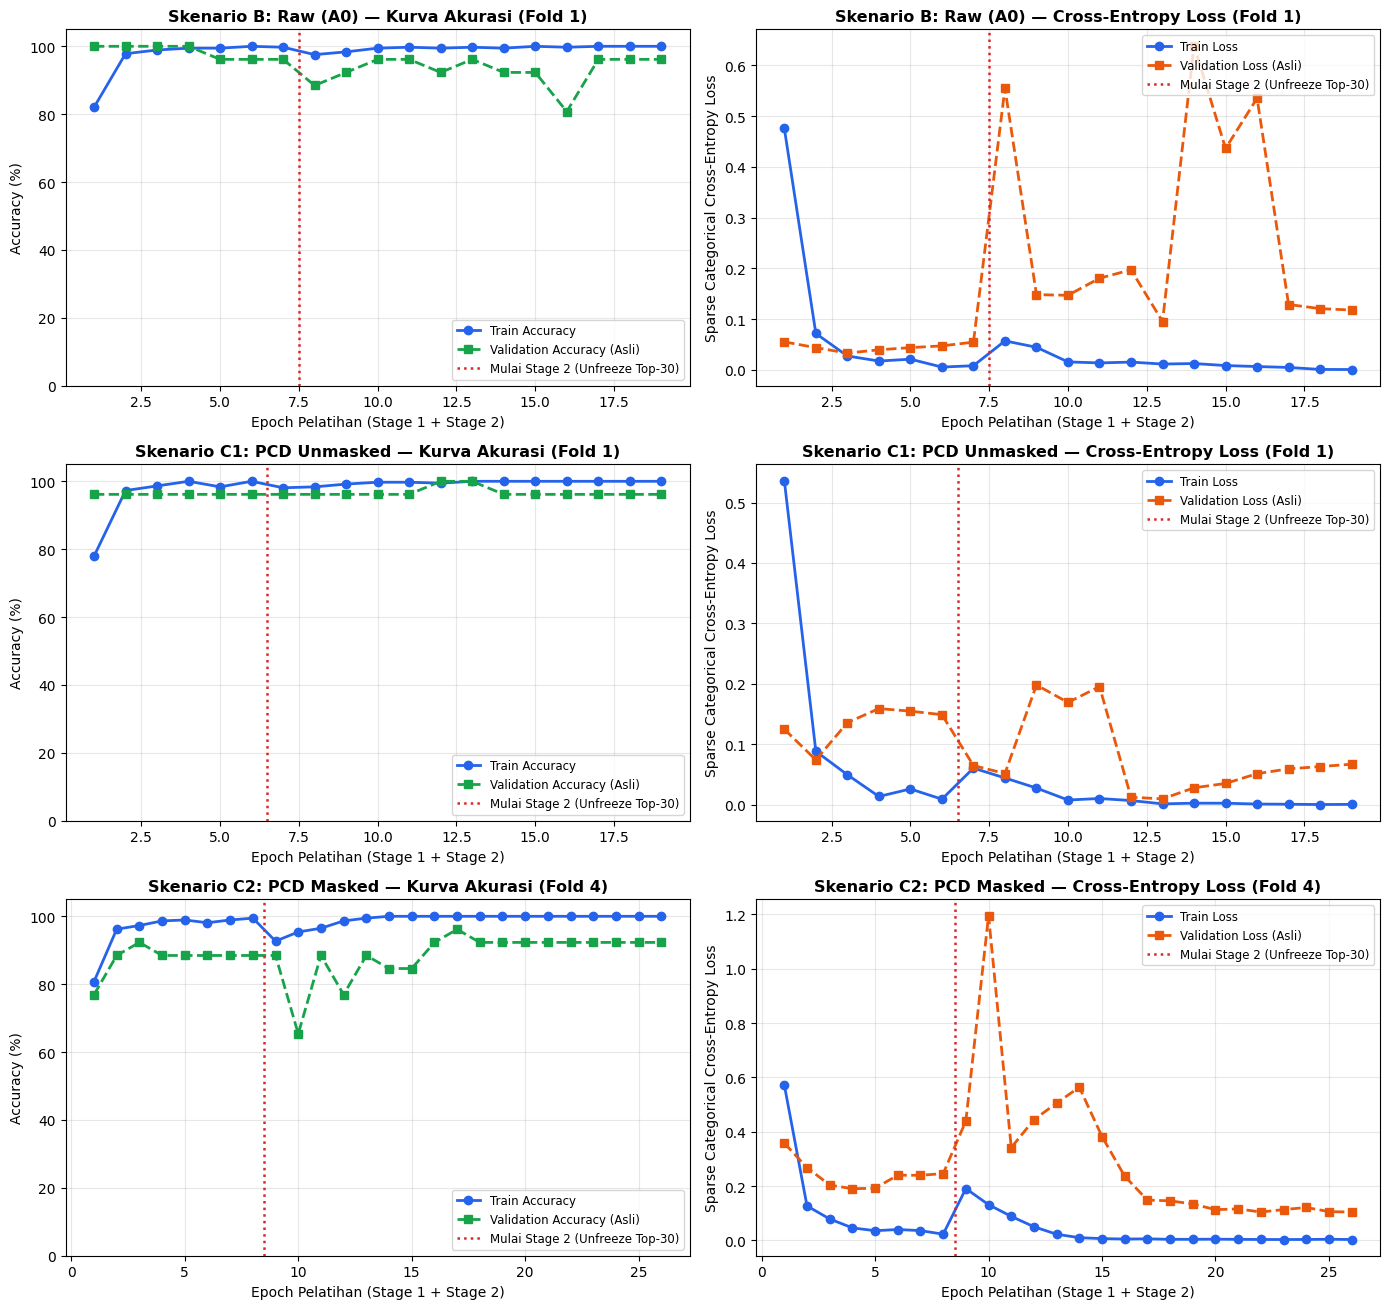

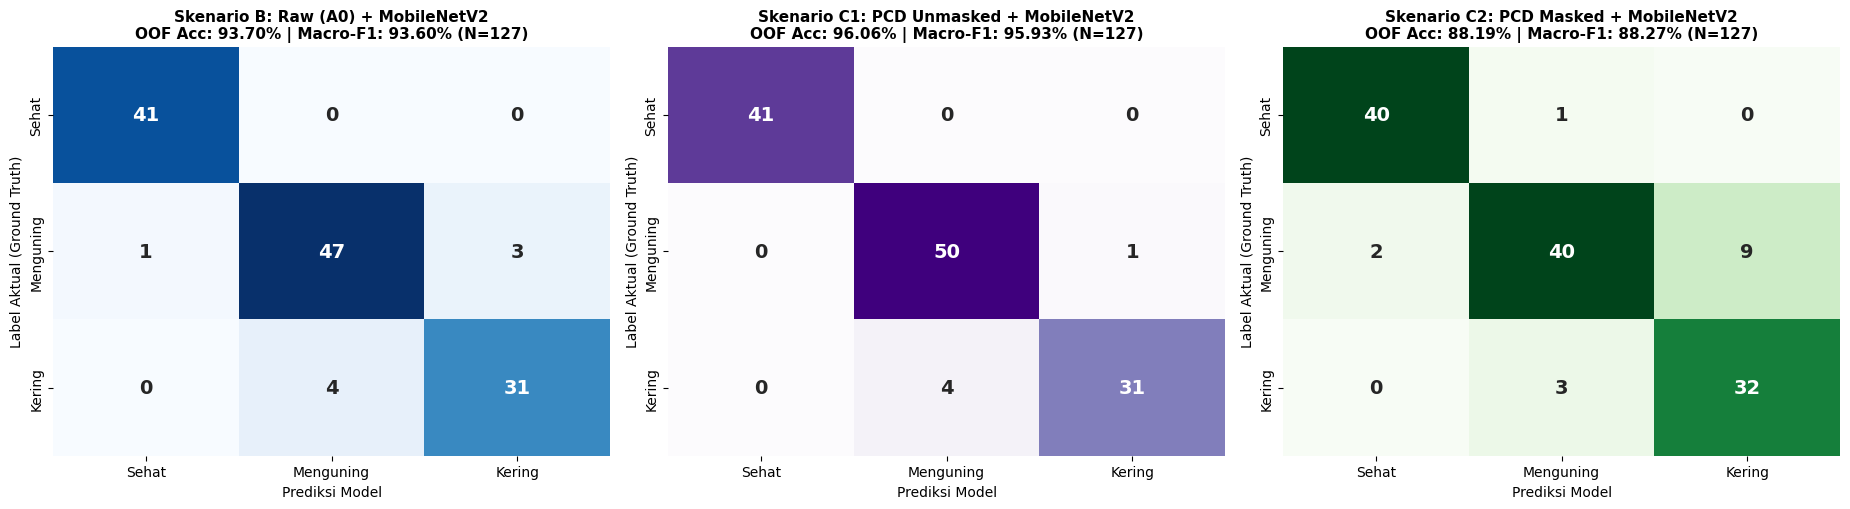


=== CLASSIFICATION REPORT PER KELAS (SKENARIO B: RAW (A0) + MOBILENETV2, N=127 ASLI) ===
              precision    recall  f1-score   support

       Sehat     0.9762    1.0000    0.9880        41
   Menguning     0.9216    0.9216    0.9216        51
      Kering     0.9118    0.8857    0.8986        35

    accuracy                         0.9370       127
   macro avg     0.9365    0.9358    0.9360       127
weighted avg     0.9365    0.9370    0.9367       127


=== CLASSIFICATION REPORT PER KELAS (SKENARIO C1: PCD UNMASKED + MOBILENETV2, N=127 ASLI) ===
              precision    recall  f1-score   support

       Sehat     1.0000    1.0000    1.0000        41
   Menguning     0.9259    0.9804    0.9524        51
      Kering     0.9688    0.8857    0.9254        35

    accuracy                         0.9606       127
   macro avg     0.9649    0.9554    0.9593       127
weighted avg     0.9616    0.9606    0.9603       127


=== CLASSIFICATION REPORT PER KELAS (SKENARIO C2: PC

In [5]:
# Urutan skenario yang ditampilkan: B (Raw), C1 (PCD Unmasked), C2 (PCD Masked)
ordered_scenarios = [
    ('B: Raw Image (A0) + MobileNetV2', 'Skenario B: Raw (A0)', 'Blues'),
    ('C1: PCD Unmasked (C1) + MobileNetV2', 'Skenario C1: PCD Unmasked', 'Purples'),
    ('C2: PCD Masked (C2) + MobileNetV2', 'Skenario C2: PCD Masked', 'Greens'),
]
active_scenarios = [(k, lbl, cmap) for k, lbl, cmap in ordered_scenarios if k in dl_histories]

# 1. GRAFIK KURVA TRAINING & VALIDATION (SEMUA SKENARIO: B vs C1 vs C2)
n_sc = len(active_scenarios)
fig, axes = plt.subplots(n_sc, 2, figsize=(14, 4.4 * n_sc))
if n_sc == 1:
    axes = np.expand_dims(axes, axis=0)

for row_i, (sc_key, sc_short, _) in enumerate(active_scenarios):
    best_k = dl_best_folds[sc_key]
    h1 = dl_histories[sc_key][best_k]['stage1']
    h2 = dl_histories[sc_key][best_k]['stage2']

    train_acc = h1['accuracy'] + h2['accuracy']
    val_acc   = h1['val_accuracy'] + h2['val_accuracy']
    train_loss = h1['loss'] + h2['loss']
    val_loss   = h1['val_loss'] + h2['val_loss']
    split_epoch = len(h1['accuracy'])
    epochs_range = np.arange(1, len(train_acc) + 1)

    # Panel kiri: Accuracy
    axes[row_i, 0].plot(epochs_range, np.array(train_acc) * 100, 'o-', color='#2563eb', linewidth=2, label='Train Accuracy')
    axes[row_i, 0].plot(epochs_range, np.array(val_acc) * 100, 's--', color='#16a34a', linewidth=2, label='Validation Accuracy (Asli)')
    axes[row_i, 0].axvline(split_epoch + 0.5, color='#dc2626', linestyle=':', linewidth=1.8, label='Mulai Stage 2 (Unfreeze Top-30)')
    axes[row_i, 0].set_title(f'{sc_short} — Kurva Akurasi (Fold {best_k+1})', fontsize=11.5, fontweight='bold')
    axes[row_i, 0].set_xlabel('Epoch Pelatihan (Stage 1 + Stage 2)')
    axes[row_i, 0].set_ylabel('Accuracy (%)')
    axes[row_i, 0].set_ylim([0, 105])
    axes[row_i, 0].grid(True, alpha=0.3)
    axes[row_i, 0].legend(loc='lower right', fontsize=8.5)

    # Panel kanan: Loss
    axes[row_i, 1].plot(epochs_range, train_loss, 'o-', color='#2563eb', linewidth=2, label='Train Loss')
    axes[row_i, 1].plot(epochs_range, val_loss, 's--', color='#ea580c', linewidth=2, label='Validation Loss (Asli)')
    axes[row_i, 1].axvline(split_epoch + 0.5, color='#dc2626', linestyle=':', linewidth=1.8, label='Mulai Stage 2 (Unfreeze Top-30)')
    axes[row_i, 1].set_title(f'{sc_short} — Cross-Entropy Loss (Fold {best_k+1})', fontsize=11.5, fontweight='bold')
    axes[row_i, 1].set_xlabel('Epoch Pelatihan (Stage 1 + Stage 2)')
    axes[row_i, 1].set_ylabel('Sparse Categorical Cross-Entropy Loss')
    axes[row_i, 1].grid(True, alpha=0.3)
    axes[row_i, 1].legend(loc='upper right', fontsize=8.5)

plt.tight_layout()
curve_fig_path = os.path.join(OUT_BASE, 'P2_Slide12_MobileNetV2_Training_Curves.png')
plt.savefig('P2_Slide12_MobileNetV2_Training_Curves.png', dpi=300)
plt.savefig(curve_fig_path, dpi=300)
plt.show()

# 2. GRAFIK CONFUSION MATRIX 3x3 OOF (KOMPARASI B vs C1 vs C2)
fig, axes = plt.subplots(1, n_sc, figsize=(6.2 * n_sc, 5.2))
if n_sc == 1:
    axes = [axes]

for col_i, (sc_key, sc_short, cmap_name) in enumerate(active_scenarios):
    oof_df = dl_oof_dict[sc_key]
    cm = confusion_matrix(oof_df['y_true'], oof_df['y_pred'], labels=CLASS_NAMES)
    acc_oof = accuracy_score(oof_df['y_true'], oof_df['y_pred']) * 100
    f1_oof  = f1_score(oof_df['y_true'], oof_df['y_pred'], average='macro') * 100

    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap_name, cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                annot_kws={'size': 14, 'weight': 'bold'}, ax=axes[col_i])
    axes[col_i].set_title(f'{sc_short} + MobileNetV2\nOOF Acc: {acc_oof:.2f}% | Macro-F1: {f1_oof:.2f}% (N=127)', fontsize=11, fontweight='bold')
    axes[col_i].set_xlabel('Prediksi Model')
    axes[col_i].set_ylabel('Label Aktual (Ground Truth)')

plt.tight_layout()
cm_fig_path = os.path.join(OUT_BASE, 'P2_Slide12_MobileNetV2_Confusion_Matrix.png')
plt.savefig('P2_Slide12_MobileNetV2_Confusion_Matrix.png', dpi=300)
plt.savefig(cm_fig_path, dpi=300)
plt.show()

for sc_key, sc_short, _ in active_scenarios:
    oof_df = dl_oof_dict[sc_key]
    print(f'\n=== CLASSIFICATION REPORT PER KELAS ({sc_short.upper()} + MOBILENETV2, N=127 ASLI) ===')
    print(classification_report(oof_df['y_true'], oof_df['y_pred'], labels=CLASS_NAMES, target_names=CLASS_NAMES, digits=4))

## 5. Visual Explainability (*Grad-CAM* Komparatif: B vs C1 vs C2)
**Tujuan:**
- Menghitung peta aktivasi **Grad-CAM (*Gradient-weighted Class Activation Mapping*)** pada layer konvolusi terakhir `MobileNetV2` (`out_relu`, resolusi $7 \times 7$) untuk sampel citra uji asli dari masing-masing kelas (`Sehat`, `Menguning`, `Kering`) di seluruh skenario (**B**, **C1**, dan **C2**).
- **Makna Ilmiah:** Melalui visualisasi komparatif *heatmap* Grad-CAM (`P2_Slide12_GradCAM_Preview.png`), kita dapat memverifikasi secara visual perbedaan fokus atensi CNN pada citra mentah (**B**), citra PCD tanpa hapus latar (**C1**), dan citra PCD dengan hapus latar (**C2**).

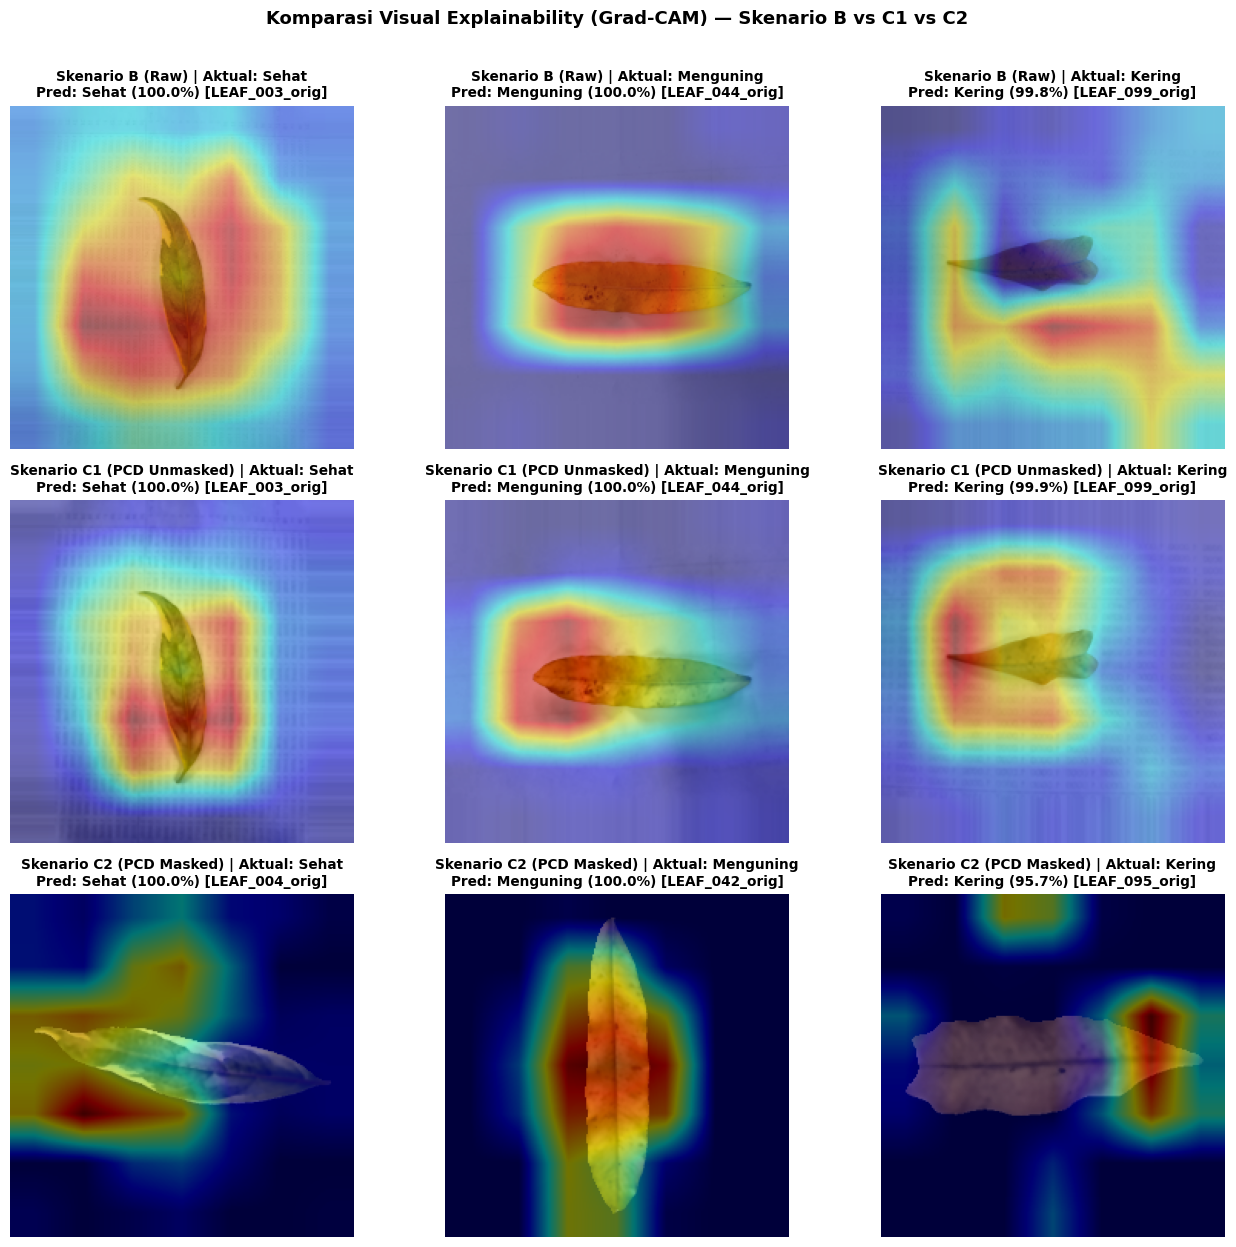

Selesai! Seluruh grafik komparasi 3 skenario & artefak Deep Learning telah tersimpan di Google Drive.


In [6]:
def compute_gradcam_heatmap(img_tensor_batch, model, last_conv_layer_name='out_relu', pred_index=None):
    """Menghitung heatmap Grad-CAM ternormalisasi [0, 1] untuk satu citra."""
    grad_model = models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_tensor_batch)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap).numpy()
    heatmap = np.maximum(heatmap, 0)
    if np.max(heatmap) > 0:
        heatmap = heatmap / np.max(heatmap)
    return heatmap, predictions.numpy()[0]

def overlay_gradcam_on_image(img_bgr, heatmap, alpha=0.45):
    """Menempelkan colormap JET Grad-CAM ke atas citra asli."""
    heatmap_resized = cv2.resize(heatmap, (img_bgr.shape[1], img_bgr.shape[0]))
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    superimposed = cv2.addWeighted(img_bgr, 1 - alpha, heatmap_color, alpha, 0)
    return cv2.cvtColor(superimposed, cv2.COLOR_BGR2RGB)

# Tampilkan perbandingan Grad-CAM untuk seluruh skenario (B, C1, C2) pada 3 sampel uji asli (1 per kelas)
ordered_gcam = [
    ('B: Raw Image (A0) + MobileNetV2', 'Skenario B (Raw)', 'path_A0_raw'),
    ('C1: PCD Unmasked (C1) + MobileNetV2', 'Skenario C1 (PCD Unmasked)', 'path_C1_nomask'),
    ('C2: PCD Masked (C2) + MobileNetV2', 'Skenario C2 (PCD Masked)', 'path_C2_masked'),
]
active_gcam = [(k, lbl, pcol) for k, lbl, pcol in ordered_gcam if k in dl_best_model_paths]

fig, axes = plt.subplots(len(active_gcam), 3, figsize=(13.5, 4.1 * len(active_gcam)))
if len(active_gcam) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_i, (sc_key, sc_short, path_col) in enumerate(active_gcam):
    sc_model = models.load_model(dl_best_model_paths[sc_key])
    best_k = dl_best_folds[sc_key]
    test_df_fold = df_master_p2[(df_master_p2['fold'] == best_k) & (df_master_p2['is_augmented'] == 0)].copy()

    for col_i, cls_name in enumerate(CLASS_NAMES):
        sub_cls = test_df_fold[test_df_fold['label'] == cls_name]
        row_sample = sub_cls.iloc[0]
        global_idx = row_sample.name

        img_tensor = np.expand_dims(X_DATA_DICT[sc_key][global_idx], axis=0)
        heatmap, probs = compute_gradcam_heatmap(img_tensor, sc_model, last_conv_layer_name='out_relu')

        pred_cls = IDX_TO_LABEL[int(np.argmax(probs))]
        conf_pct = float(np.max(probs)) * 100

        img_bgr = cv2.imread(row_sample[path_col])
        img_cam_rgb = overlay_gradcam_on_image(img_bgr, heatmap, alpha=0.45)

        axes[row_i, col_i].imshow(img_cam_rgb)
        axes[row_i, col_i].set_title(
            f'{sc_short} | Aktual: {cls_name}\nPred: {pred_cls} ({conf_pct:.1f}%) [{row_sample["sample_id"]}]',
            fontsize=9.8, fontweight='bold'
        )
        axes[row_i, col_i].axis('off')

plt.suptitle('Komparasi Visual Explainability (Grad-CAM) — Skenario B vs C1 vs C2', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
gradcam_fig_path = os.path.join(OUT_BASE, 'P2_Slide12_GradCAM_Preview.png')
plt.savefig('P2_Slide12_GradCAM_Preview.png', dpi=300, bbox_inches='tight')
plt.savefig(gradcam_fig_path, dpi=300, bbox_inches='tight')
plt.show()

print('Selesai! Seluruh grafik komparasi 3 skenario & artefak Deep Learning telah tersimpan di Google Drive.')

## 6. Eksplorasi Pretrained Object Detection: SSD MobileNet (`ssdlite320_mobilenet_v3_large`) & Grafik Training/Validation
**Tujuan:**
- Mengeksplorasi model *pretrained object detection* **SSD MobileNet** (`torchvision.models.detection.ssdlite320_mobilenet_v3_large`) pada citra `A0_raw` menggunakan *bounding box* daun yang diekstrak otomatis dari `masks/`.
- Mempertahankan protokol **Anti-Leakage** (`fold == 0 & is_augmented == 0` sebagai Test Set, `fold != 0` dibagi berdasarkan `parent_id` menjadi Train & Val murni citra asli).
- Menghasilkan **Grafik Training vs Validation Accuracy & Loss per epoch** (`P2_Slide12_SSD_MobileNet_Training_Curves.png`) untuk kebutuhan presentasi PPT, visualisasi deteksi (`P2_Slide12_SSD_MobileNet_Detection_Preview.png`), serta bobot model `best_ssd_mobilenet.pth` untuk *real-time webcam testing* di Python.

PyTorch Device untuk SSD MobileNet: cuda
SSD MobileNet Split -> Train: 367 | Val (Asli): 26 | Test (Asli): 26
Downloading: "https://download.pytorch.org/models/ssdlite320_mobilenet_v3_large_coco-a79551df.pth" to /root/.cache/torch/hub/checkpoints/ssdlite320_mobilenet_v3_large_coco-a79551df.pth


100%|██████████| 13.4M/13.4M [00:00<00:00, 227MB/s]


[SSD MobileNet] Epoch 01/8 | Train Loss: 5.8280 | Val Loss: 4.5353 | Train Acc: 48.23% | Val Acc: 46.15%
[SSD MobileNet] Epoch 02/8 | Train Loss: 3.3267 | Val Loss: 3.0458 | Train Acc: 65.12% | Val Acc: 65.38%
[SSD MobileNet] Epoch 03/8 | Train Loss: 2.4021 | Val Loss: 2.6998 | Train Acc: 73.57% | Val Acc: 84.62%
[SSD MobileNet] Epoch 04/8 | Train Loss: 1.8853 | Val Loss: 2.4596 | Train Acc: 86.92% | Val Acc: 88.46%
[SSD MobileNet] Epoch 05/8 | Train Loss: 1.5150 | Val Loss: 2.5190 | Train Acc: 94.82% | Val Acc: 92.31%
[SSD MobileNet] Epoch 06/8 | Train Loss: 1.2271 | Val Loss: 2.4718 | Train Acc: 96.46% | Val Acc: 96.15%
[SSD MobileNet] Epoch 07/8 | Train Loss: 1.0691 | Val Loss: 2.4299 | Train Acc: 97.55% | Val Acc: 96.15%
[SSD MobileNet] Epoch 08/8 | Train Loss: 1.0119 | Val Loss: 2.4262 | Train Acc: 98.09% | Val Acc: 96.15%

=== HASIL TEST SET SSD MOBILENET (Fold 0 Asli, N=26) ===
Test Top-1 Detection Accuracy: 100.00% | Macro-F1: 100.00%
Model tersimpan di: /content/drive/MyDrive/

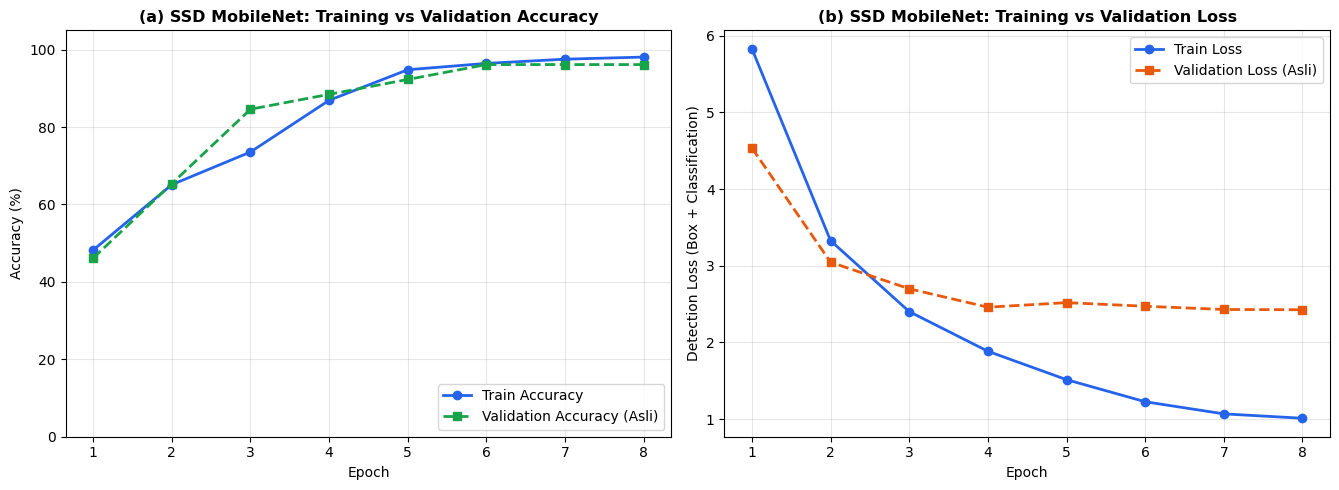

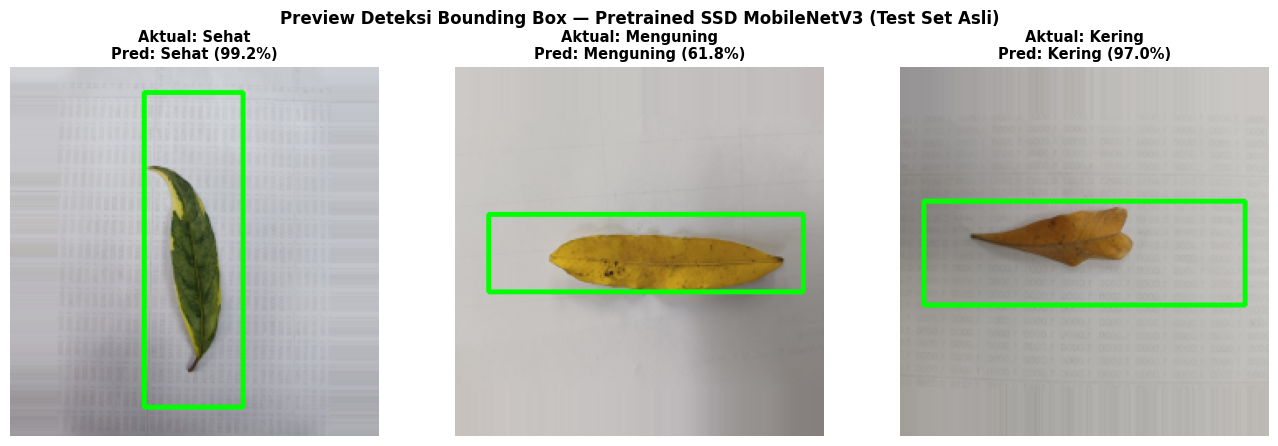

In [7]:
from functools import partial
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights
from torchvision.models.detection.ssdlite import SSDLiteClassificationHead

torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch Device untuk SSD MobileNet: {device}')

def extract_bbox_from_mask(mask_path, img_w=224, img_h=224):
    """Ekstrak bounding box [xmin, ymin, xmax, ymax] dari mask biner daun."""
    m = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if m is None:
        return [10.0, 10.0, float(img_w - 10), float(img_h - 10)]
    ys, xs = np.where(m > 127)
    if len(xs) == 0 or len(ys) == 0:
        return [10.0, 10.0, float(img_w - 10), float(img_h - 10)]
    xmin, xmax = float(np.min(xs)), float(np.max(xs))
    ymin, ymax = float(np.min(ys)), float(np.max(ys))
    if xmax - xmin < 4:
        xmax = min(float(img_w - 1), xmin + 4.0)
    if ymax - ymin < 4:
        ymax = min(float(img_h - 1), ymin + 4.0)
    return [xmin, ymin, xmax, ymax]

class LeafDetectionDataset(Dataset):
    def __init__(self, df_sub):
        self.df = df_sub.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_bgr = cv2.imread(str(row['path_A0_raw']))
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w, _ = img_rgb.shape
        img_tensor = torch.from_numpy(img_rgb).permute(2, 0, 1).float() / 255.0

        bbox = extract_bbox_from_mask(row['path_mask'], img_w=w, img_h=h)
        # Class index +1 karena 0 dicadangkan untuk background di SSD torchvision
        cls_id = int(row['label_idx']) + 1
        target = {
            'boxes': torch.tensor([bbox], dtype=torch.float32),
            'labels': torch.tensor([cls_id], dtype=torch.int64)
        }
        return img_tensor, target

def ssd_collate_fn(batch):
    return tuple(zip(*batch))

# Split Anti-Leakage: Test = fold 0 asli, Dev = fold != 0 dibagi berdasar parent_id
df_ssd_test = df_master_p2[(df_master_p2['fold'] == 0) & (df_master_p2['is_augmented'] == 0)].reset_index(drop=True)
df_ssd_dev  = df_master_p2[df_master_p2['fold'] != 0].reset_index(drop=True)

sgkf_ssd = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
tr_idx_ssd, va_idx_ssd = next(sgkf_ssd.split(df_ssd_dev, df_ssd_dev['label_idx'].values, groups=df_ssd_dev['parent_id'].values))
df_ssd_train = df_ssd_dev.iloc[tr_idx_ssd].reset_index(drop=True)
df_ssd_val   = df_ssd_dev.iloc[va_idx_ssd]
df_ssd_val   = df_ssd_val[df_ssd_val['is_augmented'] == 0].reset_index(drop=True)

print(f'SSD MobileNet Split -> Train: {len(df_ssd_train)} | Val (Asli): {len(df_ssd_val)} | Test (Asli): {len(df_ssd_test)}')

train_loader_ssd = DataLoader(LeafDetectionDataset(df_ssd_train), batch_size=8, shuffle=True, collate_fn=ssd_collate_fn)
val_loader_ssd   = DataLoader(LeafDetectionDataset(df_ssd_val), batch_size=8, shuffle=False, collate_fn=ssd_collate_fn)
test_loader_ssd  = DataLoader(LeafDetectionDataset(df_ssd_test), batch_size=8, shuffle=False, collate_fn=ssd_collate_fn)

# Inisialisasi Pretrained SSDLite320 MobileNetV3-Large (4 kelas: background + 3 kelas daun)
ssd_model = ssdlite320_mobilenet_v3_large(
    weights=SSDLite320_MobileNet_V3_Large_Weights.DEFAULT,
    trainable_backbone_layers=3
)
num_classes_ssd = len(CLASS_NAMES) + 1
in_channels_list = [672, 480, 512, 256, 256, 128]
num_anchors_list = ssd_model.anchor_generator.num_anchors_per_location()
ssd_model.head.classification_head = SSDLiteClassificationHead(
    in_channels=in_channels_list,
    num_anchors=num_anchors_list,
    num_classes=num_classes_ssd,
    norm_layer=partial(nn.BatchNorm2d, eps=0.001, momentum=0.03)
)
ssd_model.to(device)

optimizer_ssd = torch.optim.AdamW(ssd_model.parameters(), lr=5e-4, weight_decay=1e-4)
EPOCHS_SSD = 8
scheduler_ssd = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_ssd, T_max=EPOCHS_SSD)

def evaluate_ssd_cls_acc(model, loader, dev):
    """Hitung akurasi klasifikasi top-1 bounding box pada loader."""
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for imgs, targets in loader:
            imgs = [im.to(dev) for im in imgs]
            preds = model(imgs)
            for p, t in zip(preds, targets):
                gt_cls = int(t['labels'][0].item()) - 1
                y_true.append(gt_cls)
                if len(p['labels']) > 0:
                    top_idx = int(torch.argmax(p['scores']).item())
                    pred_cls = int(p['labels'][top_idx].item()) - 1
                    y_pred.append(pred_cls if 0 <= pred_cls < len(CLASS_NAMES) else 0)
                else:
                    y_pred.append(-1)
    acc = accuracy_score(y_true, y_pred) * 100.0
    return acc, y_true, y_pred

def compute_ssd_val_loss(model, loader, dev):
    """Hitung validation loss dengan mode train() tanpa update gradien."""
    model.train()
    total_loss, steps = 0.0, 0
    with torch.no_grad():
        for imgs, targets in loader:
            imgs = [im.to(dev) for im in imgs]
            targets_dev = [{k: v.to(dev) for k, v in t.items()} for t in targets]
            loss_dict = model(imgs, targets_dev)
            loss = sum(loss_dict.values())
            total_loss += float(loss.item())
            steps += 1
    return total_loss / max(steps, 1)

ssd_hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss_ssd = float('inf')
best_ssd_path = os.path.join(MODEL_DIR, 'best_ssd_mobilenet.pth')

for ep in range(1, EPOCHS_SSD + 1):
    ssd_model.train()
    tr_loss, tr_steps = 0.0, 0
    for imgs, targets in train_loader_ssd:
        imgs = [im.to(device) for im in imgs]
        targets_dev = [{k: v.to(device) for k, v in t.items()} for t in targets]
        optimizer_ssd.zero_grad()
        loss_dict = ssd_model(imgs, targets_dev)
        loss = sum(loss_dict.values())
        loss.backward()
        optimizer_ssd.step()
        tr_loss += float(loss.item())
        tr_steps += 1
    scheduler_ssd.step()

    avg_tr_loss = tr_loss / max(tr_steps, 1)
    avg_va_loss = compute_ssd_val_loss(ssd_model, val_loader_ssd, device)
    tr_acc, _, _ = evaluate_ssd_cls_acc(ssd_model, train_loader_ssd, device)
    va_acc, _, _ = evaluate_ssd_cls_acc(ssd_model, val_loader_ssd, device)

    ssd_hist['train_loss'].append(avg_tr_loss)
    ssd_hist['val_loss'].append(avg_va_loss)
    ssd_hist['train_acc'].append(tr_acc)
    ssd_hist['val_acc'].append(va_acc)

    print(f'[SSD MobileNet] Epoch {ep:02d}/{EPOCHS_SSD} | Train Loss: {avg_tr_loss:.4f} | Val Loss: {avg_va_loss:.4f} | Train Acc: {tr_acc:.2f}% | Val Acc: {va_acc:.2f}%')
    if avg_va_loss < best_val_loss_ssd:
        best_val_loss_ssd = avg_va_loss
        torch.save(ssd_model.state_dict(), best_ssd_path)

# Muat bobot terbaik & evaluasi di Test Set (fold 0 asli)
ssd_model.load_state_dict(torch.load(best_ssd_path, map_location=device))
test_acc_ssd, y_true_ssd, y_pred_ssd = evaluate_ssd_cls_acc(ssd_model, test_loader_ssd, device)
test_f1_ssd = f1_score(y_true_ssd, y_pred_ssd, average='macro', zero_division=0) * 100.0
print(f'\n=== HASIL TEST SET SSD MOBILENET (Fold 0 Asli, N={len(df_ssd_test)}) ===')
print(f'Test Top-1 Detection Accuracy: {test_acc_ssd:.2f}% | Macro-F1: {test_f1_ssd:.2f}%')
print(f'Model tersimpan di: {best_ssd_path}')

# Plot Grafik Training vs Validation Accuracy & Loss per Epoch (Siap PPT)
ep_axis = np.arange(1, EPOCHS_SSD + 1)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
axes[0].plot(ep_axis, ssd_hist['train_acc'], 'o-', color='#2563eb', linewidth=2, label='Train Accuracy')
axes[0].plot(ep_axis, ssd_hist['val_acc'], 's--', color='#16a34a', linewidth=2, label='Validation Accuracy (Asli)')
axes[0].set_title('(a) SSD MobileNet: Training vs Validation Accuracy', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim([0, 105])
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='lower right')

axes[1].plot(ep_axis, ssd_hist['train_loss'], 'o-', color='#2563eb', linewidth=2, label='Train Loss')
axes[1].plot(ep_axis, ssd_hist['val_loss'], 's--', color='#ea580c', linewidth=2, label='Validation Loss (Asli)')
axes[1].set_title('(b) SSD MobileNet: Training vs Validation Loss', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Detection Loss (Box + Classification)')
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper right')

plt.tight_layout()
ssd_curve_path = os.path.join(OUT_BASE, 'P2_Slide12_SSD_MobileNet_Training_Curves.png')
plt.savefig('P2_Slide12_SSD_MobileNet_Training_Curves.png', dpi=300)
plt.savefig(ssd_curve_path, dpi=300)
plt.show()

# Preview Deteksi Bounding Box SSD MobileNet pada 3 sampel uji (1 per kelas)
ssd_model.eval()
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5))
for col_i, cls_name in enumerate(CLASS_NAMES):
    sub_df = df_ssd_test[df_ssd_test['label'] == cls_name]
    sample_row = sub_df.iloc[0]
    img_bgr = cv2.imread(str(sample_row['path_A0_raw']))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_t = torch.from_numpy(img_rgb).permute(2, 0, 1).float().to(device) / 255.0
    with torch.no_grad():
        out = ssd_model([img_t])[0]
    disp = img_rgb.copy()
    if len(out['boxes']) > 0:
        best_i = int(torch.argmax(out['scores']).item())
        box = out['boxes'][best_i].cpu().numpy().astype(int)
        score = float(out['scores'][best_i].item())
        pred_id = int(out['labels'][best_i].item()) - 1
        pred_lbl = IDX_TO_LABEL.get(pred_id, 'Unknown')
        cv2.rectangle(disp, (box[0], box[1]), (box[2], box[3]), (0, 255, 0), 2)
        title_txt = f'Aktual: {cls_name}\nPred: {pred_lbl} ({score*100:.1f}%)'
    else:
        title_txt = f'Aktual: {cls_name}\nPred: Tidak Terdeteksi'
    axes[col_i].imshow(disp)
    axes[col_i].set_title(title_txt, fontsize=10.5, fontweight='bold')
    axes[col_i].axis('off')

plt.suptitle('Preview Deteksi Bounding Box — Pretrained SSD MobileNetV3 (Test Set Asli)', fontsize=12, fontweight='bold')
plt.tight_layout()
ssd_det_path = os.path.join(OUT_BASE, 'P2_Slide12_SSD_MobileNet_Detection_Preview.png')
plt.savefig('P2_Slide12_SSD_MobileNet_Detection_Preview.png', dpi=300)
plt.savefig(ssd_det_path, dpi=300)
plt.show()

## 7. Eksplorasi Pretrained YOLOv8n (`ultralytics`) & Perbandingan dengan SSD MobileNet
**Tujuan:**
- Mengeksplorasi **YOLOv8n** (*pretrained* COCO) pada split Anti-Leakage yang sama (`df_ssd_train`, `df_ssd_val`, `df_ssd_test`) dengan mengekstrak label bounding box format YOLO (`class_id x_center y_center width height`) dari `masks/`.
- Menghasilkan **Grafik Training vs Validation Loss & mAP@50 per epoch** (`P2_Slide12_YOLOv8_Training_Curves.png`).
- Membandingkan **SSD MobileNet** vs **YOLOv8n** secara objektif berdasarkan **Akurasi Test Set**, **Macro-F1**, **Kecepatan Inferensi (FPS/ms)**, dan **Ukuran Model (MB)** untuk menentukan model terbaik bagi *real-time testing*.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/yolo_leaf_dataset/leaf_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epoch

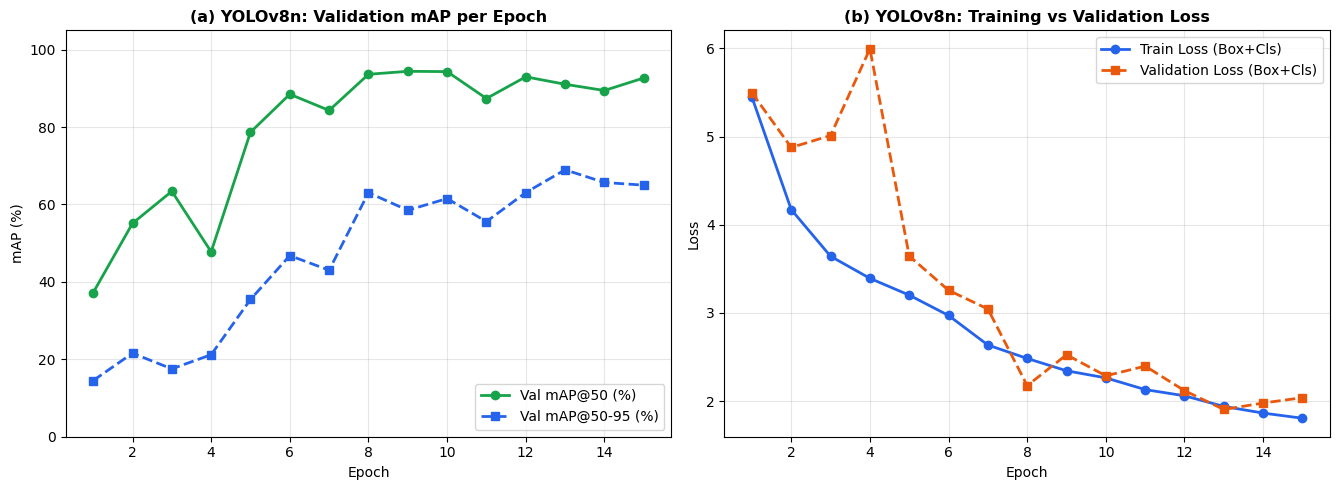


=== PERBANDINGAN OBJECT DETECTION: SSD MOBILENET VS YOLOV8N (FOLD 0 ASLI) ===
Model Object Detection  Test Accuracy (%)  Test Macro-F1 (%)  Latency (ms/img)  Est. FPS  Model Size (MB)
 SSD MobileNetV3-Large              100.0              100.0             17.89      55.9             8.82
 YOLOv8n (ultralytics)              100.0              100.0             14.42      69.3             6.16


In [8]:
import shutil
import subprocess
import sys
import time

try:
    from ultralytics import YOLO
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'])
    from ultralytics import YOLO

YOLO_DATA_DIR = os.path.join(OUT_BASE, 'yolo_leaf_dataset')
for split_name in ['train', 'val', 'test']:
    os.makedirs(os.path.join(YOLO_DATA_DIR, 'images', split_name), exist_ok=True)
    os.makedirs(os.path.join(YOLO_DATA_DIR, 'labels', split_name), exist_ok=True)

def export_df_to_yolo(df_sub, split_name):
    for idx, row in df_sub.iterrows():
        img_src = str(row['path_A0_raw'])
        fname = f"{row['sample_id']}.png"
        img_dst = os.path.join(YOLO_DATA_DIR, 'images', split_name, fname)
        lbl_dst = os.path.join(YOLO_DATA_DIR, 'labels', split_name, f"{row['sample_id']}.txt")
        shutil.copy2(img_src, img_dst)

        img_tmp = cv2.imread(img_src)
        h, w, _ = img_tmp.shape
        xmin, ymin, xmax, ymax = extract_bbox_from_mask(row['path_mask'], img_w=w, img_h=h)
        xc = ((xmin + xmax) / 2.0) / w
        yc = ((ymin + ymax) / 2.0) / h
        bw = (xmax - xmin) / w
        bh = (ymax - ymin) / h
        cls_id = int(row['label_idx'])
        with open(lbl_dst, 'w', encoding='utf-8') as f:
            f.write(f"{cls_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")

export_df_to_yolo(df_ssd_train, 'train')
export_df_to_yolo(df_ssd_val, 'val')
export_df_to_yolo(df_ssd_test, 'test')

yaml_path = os.path.join(YOLO_DATA_DIR, 'leaf_data.yaml')
with open(yaml_path, 'w', encoding='utf-8') as f:
    f.write(f"path: {YOLO_DATA_DIR}\n")
    f.write("train: images/train\n")
    f.write("val: images/val\n")
    f.write("test: images/test\n")
    f.write("nc: 3\n")
    f.write("names: ['Sehat', 'Menguning', 'Kering']\n")

yolo_model = YOLO('yolov8n.pt')
yolo_runs_dir = os.path.join(OUT_BASE, 'runs_yolo')
yolo_results = yolo_model.train(
    data=yaml_path,
    epochs=15,
    imgsz=224,
    batch=16,
    seed=SEED,
    project=yolo_runs_dir,
    name='leaf_yolov8n',
    exist_ok=True,
    verbose=False
)

best_yolo_src = os.path.join(yolo_runs_dir, 'leaf_yolov8n', 'weights', 'best.pt')
best_yolo_dst = os.path.join(MODEL_DIR, 'best_yolov8n.pt')
if os.path.exists(best_yolo_src):
    shutil.copy2(best_yolo_src, best_yolo_dst)

# Plot Grafik Training vs Validation Loss & mAP@50 YOLOv8n per epoch
res_csv = os.path.join(yolo_runs_dir, 'leaf_yolov8n', 'results.csv')
if os.path.exists(res_csv):
    df_yres = pd.read_csv(res_csv)
    df_yres.columns = [c.strip() for c in df_yres.columns]
    ep_y = df_yres['epoch']
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
    axes[0].plot(ep_y, df_yres['metrics/mAP50(B)'] * 100, 'o-', color='#16a34a', linewidth=2, label='Val mAP@50 (%)')
    axes[0].plot(ep_y, df_yres['metrics/mAP50-95(B)'] * 100, 's--', color='#2563eb', linewidth=2, label='Val mAP@50-95 (%)')
    axes[0].set_title('(a) YOLOv8n: Validation mAP per Epoch', fontsize=11.5, fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('mAP (%)')
    axes[0].set_ylim([0, 105])
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='lower right')

    tr_tot = df_yres['train/box_loss'] + df_yres['train/cls_loss']
    va_tot = df_yres['val/box_loss'] + df_yres['val/cls_loss']
    axes[1].plot(ep_y, tr_tot, 'o-', color='#2563eb', linewidth=2, label='Train Loss (Box+Cls)')
    axes[1].plot(ep_y, va_tot, 's--', color='#ea580c', linewidth=2, label='Validation Loss (Box+Cls)')
    axes[1].set_title('(b) YOLOv8n: Training vs Validation Loss', fontsize=11.5, fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(loc='upper right')

    plt.tight_layout()
    yolo_curve_path = os.path.join(OUT_BASE, 'P2_Slide12_YOLOv8_Training_Curves.png')
    plt.savefig('P2_Slide12_YOLOv8_Training_Curves.png', dpi=300)
    plt.savefig(yolo_curve_path, dpi=300)
    plt.show()

# Evaluasi YOLOv8n di Test Set (fold 0 asli) & Benchmark Kecepatan vs SSD MobileNet
best_yolo = YOLO(best_yolo_dst)
y_true_yolo, y_pred_yolo = [], []
t_yolo_list = []
for _, row in df_ssd_test.iterrows():
    y_true_yolo.append(int(row['label_idx']))
    img_bgr = cv2.imread(str(row['path_A0_raw']))
    t0 = time.time()
    preds = best_yolo.predict(img_bgr, imgsz=224, verbose=False)
    t_yolo_list.append((time.time() - t0) * 1000.0)
    boxes = preds[0].boxes
    if len(boxes) > 0:
        top_i = int(torch.argmax(boxes.conf).item())
        y_pred_yolo.append(int(boxes.cls[top_i].item()))
    else:
        y_pred_yolo.append(-1)

acc_yolo = accuracy_score(y_true_yolo, y_pred_yolo) * 100.0
f1_yolo = f1_score(y_true_yolo, y_pred_yolo, average='macro', zero_division=0) * 100.0
ms_yolo = float(np.mean(t_yolo_list))

# Benchmark kecepatan SSD MobileNet pada gambar yang sama
ssd_model.eval()
t_ssd_list = []
for _, row in df_ssd_test.iterrows():
    img_bgr = cv2.imread(str(row['path_A0_raw']))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_t = torch.from_numpy(img_rgb).permute(2, 0, 1).float().to(device) / 255.0
    t0 = time.time()
    with torch.no_grad():
        _ = ssd_model([img_t])
    t_ssd_list.append((time.time() - t0) * 1000.0)
ms_ssd = float(np.mean(t_ssd_list))

size_ssd_mb = os.path.getsize(best_ssd_path) / (1024 * 1024)
size_yolo_mb = os.path.getsize(best_yolo_dst) / (1024 * 1024)

df_det_comp = pd.DataFrame([
    {
        'Model Object Detection': 'SSD MobileNetV3-Large',
        'Test Accuracy (%)': round(test_acc_ssd, 2),
        'Test Macro-F1 (%)': round(test_f1_ssd, 2),
        'Latency (ms/img)': round(ms_ssd, 2),
        'Est. FPS': round(1000.0 / max(ms_ssd, 1e-3), 1),
        'Model Size (MB)': round(size_ssd_mb, 2),
    },
    {
        'Model Object Detection': 'YOLOv8n (ultralytics)',
        'Test Accuracy (%)': round(acc_yolo, 2),
        'Test Macro-F1 (%)': round(f1_yolo, 2),
        'Latency (ms/img)': round(ms_yolo, 2),
        'Est. FPS': round(1000.0 / max(ms_yolo, 1e-3), 1),
        'Model Size (MB)': round(size_yolo_mb, 2),
    }
])

print('\n=== PERBANDINGAN OBJECT DETECTION: SSD MOBILENET VS YOLOV8N (FOLD 0 ASLI) ===')
print(df_det_comp.to_string(index=False))
df_det_comp.to_csv(os.path.join(OUT_BASE, 'P2_Tabel6_Komparasi_SSD_vs_YOLO.csv'), index=False)

## 8. Progress 3: Uji Generalisasi Lintas-Sesi (LOSO: Sesi 1 $\leftrightarrow$ Sesi 2) — Skenario B, C1, C2 + Waktu Latih & Latensi
**Tujuan:**
- Menguji apakah keunggulan **Skenario B (Raw)** dan **Skenario C1 (PCD Unmasked)** pada 5-Fold CV acak tetap bertahan lintas-sesi (**LOSO**: *Leave-One-Session-Out*), atau mengalami penurunan seperti pada ML Klasik akibat *background/session shortcut*.
- Menjalankan 2 arah pengujian untuk ketiga skenario (**B**, **C1**, **C2**):
  1. **`S1 -> S2`:** Latih pada seluruh data Sesi 1 (asli + augmentasi), uji murni pada citra asli Sesi 2 (`is_augmented == 0`).
  2. **`S2 -> S1`:** Latih pada seluruh data Sesi 2 (asli + augmentasi), uji murni pada citra asli Sesi 1 (`is_augmented == 0`).
- Mencatat **Waktu Latih (detik)** serta **Latensi Inferensi (ms/citra)** untuk setiap skenario, lalu mengekspor **`P3_Tabel_LOSO_DL_MobileNetV2.csv`** dan grafik **`P3_Grafik_LOSO_vs_5Fold_DL.png`**.

[B: Raw Image (A0) + MobileNetV2] S1 -> S2 (N_test=42) -> Acc: 76.19% | Macro-F1: 69.52% | Train: 60.0s | Latensi: 151.64 ms/img
[B: Raw Image (A0) + MobileNetV2] S2 -> S1 (N_test=85) -> Acc: 41.18% | Macro-F1: 39.37% | Train: 60.0s | Latensi: 119.37 ms/img
[C1: PCD Unmasked (C1) + MobileNetV2] S1 -> S2 (N_test=42) -> Acc: 26.19% | Macro-F1: 17.83% | Train: 51.3s | Latensi: 148.69 ms/img
[C1: PCD Unmasked (C1) + MobileNetV2] S2 -> S1 (N_test=85) -> Acc: 56.47% | Macro-F1: 58.00% | Train: 49.8s | Latensi: 73.46 ms/img
[C2: PCD Masked (C2) + MobileNetV2] S1 -> S2 (N_test=42) -> Acc: 61.90% | Macro-F1: 52.71% | Train: 52.1s | Latensi: 145.58 ms/img
[C2: PCD Masked (C2) + MobileNetV2] S2 -> S1 (N_test=85) -> Acc: 64.71% | Macro-F1: 65.94% | Train: 44.0s | Latensi: 75.16 ms/img

=== TABEL LOSO LINTAS-SESI MOBILENETV2 (B vs C1 vs C2) ===
                           Skenario Arah LOSO  N_Train  N_Test_Asli  Accuracy (%)  Macro-F1 (%)  Waktu Latih (s)  Latensi (ms/citra)
    B: Raw Image (A0) +

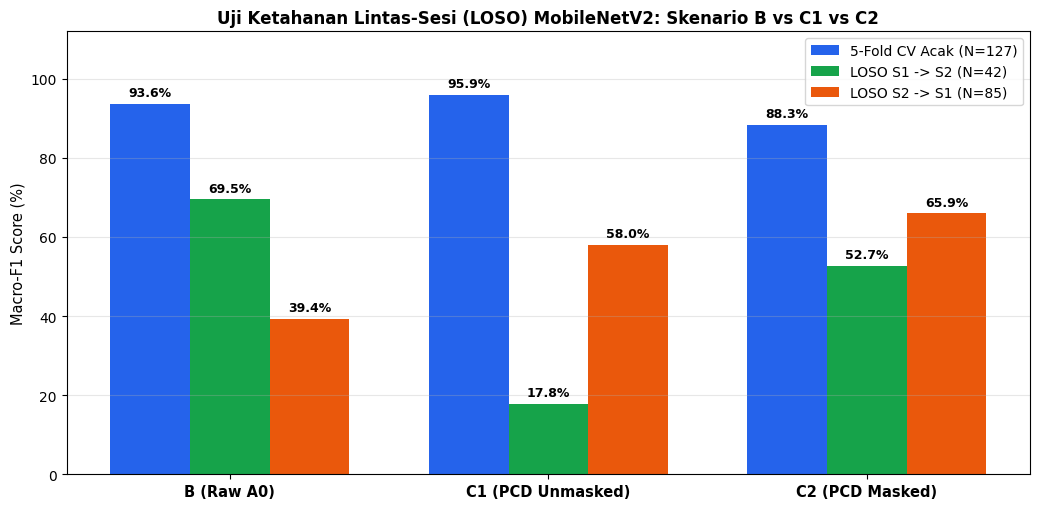

In [9]:
import time

def run_loso_mobilenetv2(X_all, df_meta, scenario_tag, train_sesi, epochs_stage1=12, epochs_stage2=18, batch_size=16):
    """Melatih MobileNetV2 pada 1 sesi penuh dan menguji murni citra asli pada sesi lainnya (Anti-Leakage)."""
    dev_mask  = (df_meta['sesi'] == train_sesi).values
    test_mask = ((df_meta['sesi'] != train_sesi) & (df_meta['is_augmented'] == 0)).values

    df_dev = df_meta[dev_mask].reset_index(drop=True)
    X_dev  = X_all[dev_mask]
    y_dev  = df_dev['label_idx'].values

    # Validation split berbasis parent_id dan hanya citra asli untuk EarlyStopping
    sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + train_sesi)
    sub_tr_idx, sub_va_idx = next(sgkf.split(X_dev, y_dev, groups=df_dev['parent_id'].values))
    orig_va_filter = (df_dev.iloc[sub_va_idx]['is_augmented'] == 0).values
    final_va_idx = sub_va_idx[orig_va_filter]

    X_train, y_train = X_dev[sub_tr_idx], y_dev[sub_tr_idx]
    X_val, y_val     = X_dev[final_va_idx], y_dev[final_va_idx]
    X_test, y_test   = X_all[test_mask], df_meta[test_mask]['label_idx'].values

    classes_unique = np.unique(y_train)
    cw_vals = compute_class_weight(class_weight='balanced', classes=classes_unique, y=y_train)
    class_weight_dict = {int(c): float(w) for c, w in zip(classes_unique, cw_vals)}

    t_train_start = time.time()
    model, base_model = build_mobilenetv2_classifier(num_classes=len(CLASS_NAMES), input_shape=(224, 224, 3))

    # Stage 1
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=epochs_stage1, batch_size=batch_size, class_weight=class_weight_dict,
        callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=0)],
        verbose=0
    )

    # Stage 2
    unfreeze_top_layers(base_model, fine_tune_from=-30)
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=epochs_stage2, batch_size=batch_size, class_weight=class_weight_dict,
        callbacks=[
            callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=0),
            callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=0)
        ],
        verbose=0
    )
    train_time_sec = time.time() - t_train_start

    # Warm-up 1 batch agar pengukuran latensi tidak bias tf.function tracing
    _ = model.predict(X_test[:1], verbose=0)
    t_inf_start = time.time()
    y_prob = model.predict(X_test, batch_size=batch_size, verbose=0)
    inf_total_ms = (time.time() - t_inf_start) * 1000.0
    latency_ms_per_img = inf_total_ms / max(len(X_test), 1)

    y_pred = np.argmax(y_prob, axis=1)
    acc = accuracy_score(y_test, y_pred) * 100.0
    f1  = f1_score(y_test, y_pred, average='macro', zero_division=0) * 100.0
    return {
        'Skenario': scenario_tag,
        'Arah LOSO': f'S{train_sesi} -> S{2 if train_sesi == 1 else 1}',
        'N_Train': len(X_train),
        'N_Test_Asli': len(X_test),
        'Accuracy (%)': round(acc, 2),
        'Macro-F1 (%)': round(f1, 2),
        'Waktu Latih (s)': round(train_time_sec, 2),
        'Latensi (ms/citra)': round(latency_ms_per_img, 2),
    }

loso_order = [
    'B: Raw Image (A0) + MobileNetV2',
    'C1: PCD Unmasked (C1) + MobileNetV2',
    'C2: PCD Masked (C2) + MobileNetV2',
]
loso_records = []
for sc_name in loso_order:
    if sc_name not in X_DATA_DICT:
        continue
    for tr_sesi in [1, 2]:
        res = run_loso_mobilenetv2(X_DATA_DICT[sc_name], df_master_p2, sc_name, train_sesi=tr_sesi)
        loso_records.append(res)
        print(f"[{res['Skenario']}] {res['Arah LOSO']} (N_test={res['N_Test_Asli']}) -> Acc: {res['Accuracy (%)']:.2f}% | Macro-F1: {res['Macro-F1 (%)']:.2f}% | Train: {res['Waktu Latih (s)']:.1f}s | Latensi: {res['Latensi (ms/citra)']:.2f} ms/img")

df_loso_dl = pd.DataFrame(loso_records)
loso_csv_path = os.path.join(OUT_BASE, 'P3_Tabel_LOSO_DL_MobileNetV2.csv')
df_loso_dl.to_csv(loso_csv_path, index=False)
df_loso_dl.to_csv('P3_Tabel_LOSO_DL_MobileNetV2.csv', index=False)

print('\n=== TABEL LOSO LINTAS-SESI MOBILENETV2 (B vs C1 vs C2) ===')
print(df_loso_dl.to_string(index=False))

# Visualisasi Perbandingan 5-Fold vs LOSO (S1->S2 & S2->S1)
short_map = {
    'B: Raw Image (A0) + MobileNetV2': 'B (Raw A0)',
    'C1: PCD Unmasked (C1) + MobileNetV2': 'C1 (PCD Unmasked)',
    'C2: PCD Masked (C2) + MobileNetV2': 'C2 (PCD Masked)',
}
labels_x, f1_5fold, f1_s12, f1_s21 = [], [], [], []
for sc_name in loso_order:
    if sc_name not in dl_oof_dict:
        continue
    labels_x.append(short_map[sc_name])
    oof_tmp = dl_oof_dict[sc_name]
    f1_5fold.append(f1_score(oof_tmp['y_true'], oof_tmp['y_pred'], average='macro') * 100.0)
    sub_l = df_loso_dl[df_loso_dl['Skenario'] == sc_name]
    f1_s12.append(float(sub_l[sub_l['Arah LOSO'] == 'S1 -> S2']['Macro-F1 (%)'].iloc[0]))
    f1_s21.append(float(sub_l[sub_l['Arah LOSO'] == 'S2 -> S1']['Macro-F1 (%)'].iloc[0]))

x_pos = np.arange(len(labels_x))
w_bar = 0.25
fig, ax = plt.subplots(figsize=(10.5, 5.2))
b1 = ax.bar(x_pos - w_bar, f1_5fold, width=w_bar, color='#2563eb', label='5-Fold CV Acak (N=127)')
b2 = ax.bar(x_pos,         f1_s12,   width=w_bar, color='#16a34a', label='LOSO S1 -> S2 (N=42)')
b3 = ax.bar(x_pos + w_bar, f1_s21,   width=w_bar, color='#ea580c', label='LOSO S2 -> S1 (N=85)')

for bars in [b1, b2, b3]:
    for bar in bars:
        h_val = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2.0, h_val + 1.2, f'{h_val:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x_pos)
ax.set_xticklabels(labels_x, fontsize=10.5, fontweight='bold')
ax.set_ylim([0, 112])
ax.set_ylabel('Macro-F1 Score (%)', fontsize=10.5)
ax.set_title('Uji Ketahanan Lintas-Sesi (LOSO) MobileNetV2: Skenario B vs C1 vs C2', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='upper right')
plt.tight_layout()

loso_fig_path = os.path.join(OUT_BASE, 'P3_Grafik_LOSO_vs_5Fold_DL.png')
plt.savefig('P3_Grafik_LOSO_vs_5Fold_DL.png', dpi=300)
plt.savefig(loso_fig_path, dpi=300)
plt.show()

## 9. Progress 3: Galeri Contoh Berhasil vs Gagal (Grad-CAM) & Perbandingan 11 Galat ML Klasik
**Tujuan:**
- Mengekspor **3 contoh prediksi benar** (1 per kelas) beserta peta aktivasi **Grad-CAM** pada MobileNetV2 Skenario C2 (`P3_Galeri_Berhasil_GradCAM_C2.png`).
- Mengekspor **seluruh foto yang salah diprediksi** oleh MobileNetV2 C2 beserta peta **Grad-CAM** (`P3_Galeri_Error_Analysis_GradCAM_C2.png`).
- Membandingkan irisan (*overlap*) galat MobileNetV2 C2 dengan **11 galat ML Klasik (Random Forest Skenario A)** di `oof_ml_A_p2.csv` untuk mengetahui apakah DL dan ML gagal pada foto transisi `Menguning / Kering` yang sama (`P3_Komparasi_Galat_DL_vs_ML.csv`).

=== ANALISIS IRISAN GALAT: MOBILENETV2 C2 VS ML KLASIK (RF SKENARIO A) ===
Total Galat ML Klasik (RF Skenario A) : 11 / 127
Total Galat DL (MobileNetV2 C2)       : 15 / 127
Salah di Keduanya (ML ∩ DL C2)        : 2 -> ['LEAF_097_orig', 'LEAF_098_orig']
Hanya Salah di ML (Diperbaiki DL C2)  : 9 -> ['LEAF_057_orig', 'LEAF_058_orig', 'LEAF_061_orig', 'LEAF_069_orig', 'LEAF_073_orig', 'LEAF_074_orig', 'LEAF_094_orig', 'LEAF_101_orig', 'LEAF_115_orig']
Hanya Salah di DL C2 (Benar di ML)    : 13 -> ['LEAF_014_orig', 'LEAF_044_orig', 'LEAF_049_orig', 'LEAF_052_orig', 'LEAF_055_orig', 'LEAF_062_orig', 'LEAF_063_orig', 'LEAF_065_orig', 'LEAF_072_orig', 'LEAF_076_orig', 'LEAF_078_orig', 'LEAF_081_orig', 'LEAF_121_orig']


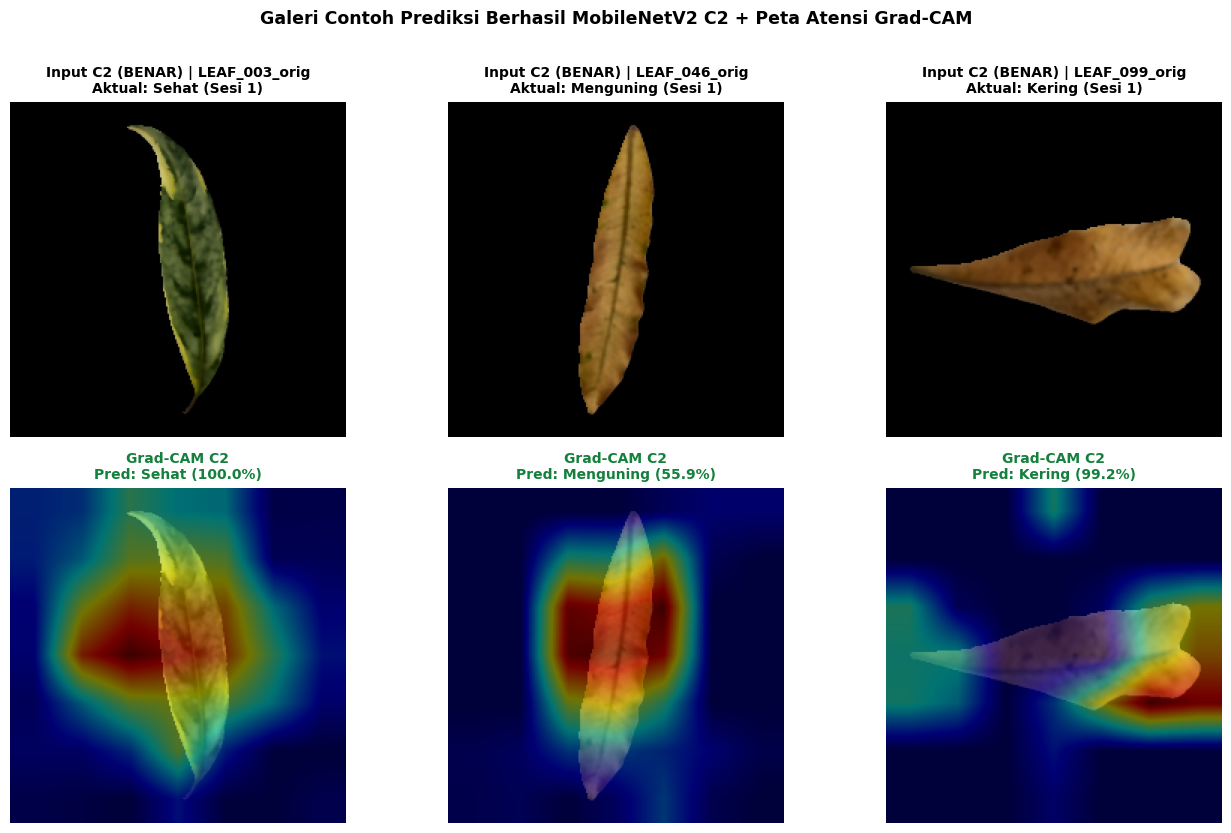

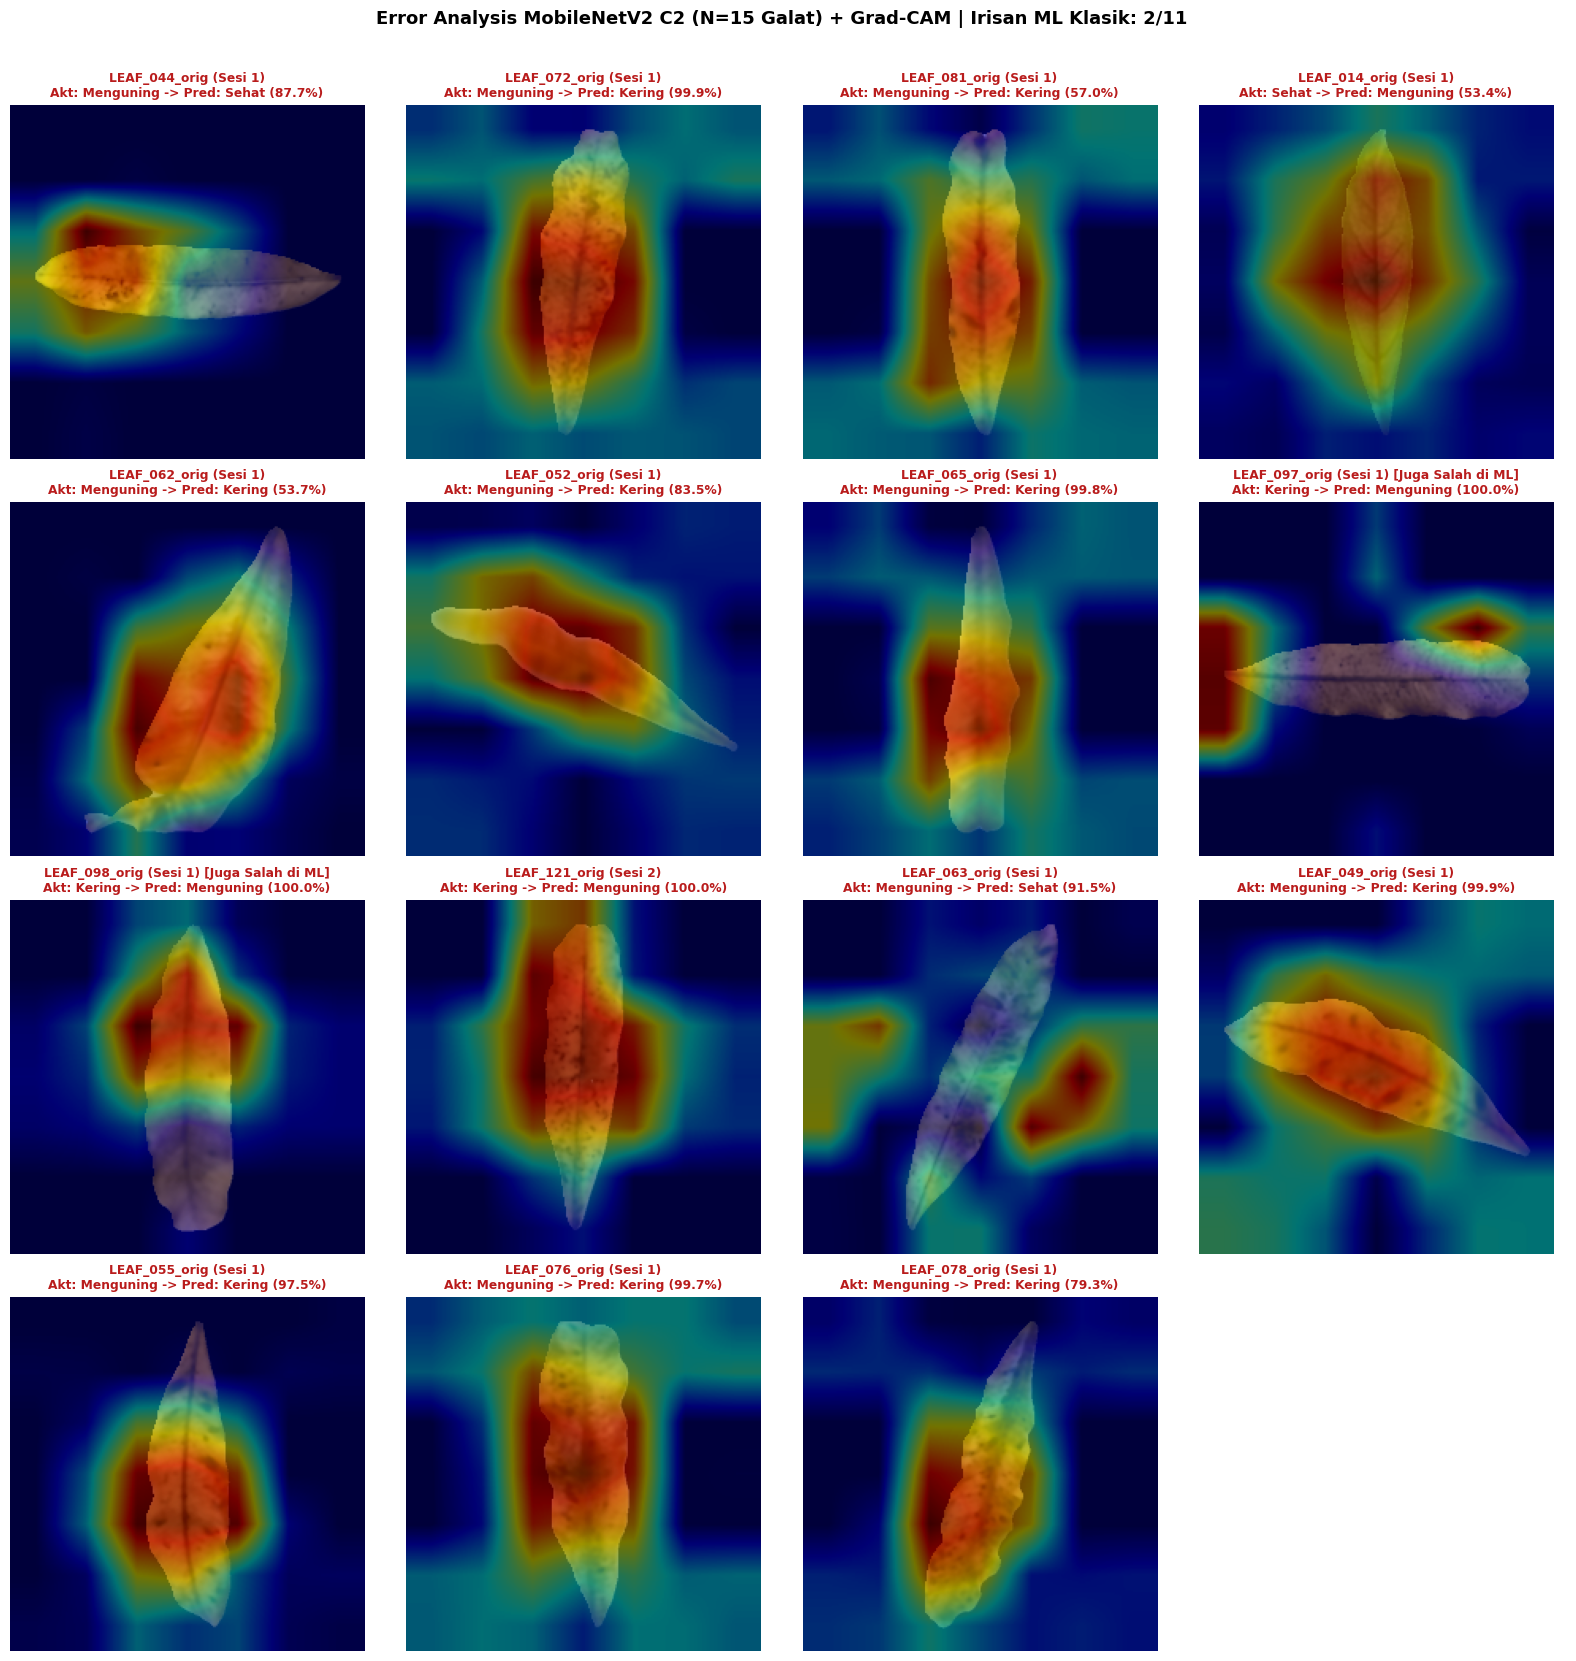

In [10]:
import math

sc_c2_key = 'C2: PCD Masked (C2) + MobileNetV2'
oof_c2_df = dl_oof_dict[sc_c2_key].copy()
oof_c2_df['dl_correct'] = (oof_c2_df['y_true'] == oof_c2_df['y_pred'])

# Gabungkan metadata path_C2_masked & parent_id
oof_c2_merged = oof_c2_df.merge(
    df_master_p2[['sample_id', 'parent_id', 'original_filename', 'fold', 'path_C2_masked']],
    on='sample_id', how='left'
)

# Muat 11 galat ML Klasik (Random Forest Skenario A) dari oof_ml_A_p2.csv
ml_oof_path = os.path.join(OUT_BASE, 'oof_ml_A_p2.csv')
if os.path.exists(ml_oof_path):
    df_ml_all = pd.read_csv(ml_oof_path)
    df_ml_rf = df_ml_all[df_ml_all['model'] == 'Random Forest'].copy()
    ml_err_ids = set(df_ml_rf[df_ml_rf['y_true'] != df_ml_rf['y_pred']]['sample_id'].values)
else:
    df_ml_rf = pd.DataFrame(columns=['sample_id', 'y_true', 'y_pred'])
    ml_err_ids = set()

dl_err_ids = set(oof_c2_merged[~oof_c2_merged['dl_correct']]['sample_id'].values)
overlap_ids = sorted(ml_err_ids.intersection(dl_err_ids))
only_ml_ids = sorted(ml_err_ids - dl_err_ids)
only_dl_ids = sorted(dl_err_ids - ml_err_ids)

print('=== ANALISIS IRISAN GALAT: MOBILENETV2 C2 VS ML KLASIK (RF SKENARIO A) ===')
print(f'Total Galat ML Klasik (RF Skenario A) : {len(ml_err_ids)} / 127')
print(f'Total Galat DL (MobileNetV2 C2)       : {len(dl_err_ids)} / 127')
print(f'Salah di Keduanya (ML ∩ DL C2)        : {len(overlap_ids)} -> {overlap_ids}')
print(f'Hanya Salah di ML (Diperbaiki DL C2)  : {len(only_ml_ids)} -> {only_ml_ids}')
print(f'Hanya Salah di DL C2 (Benar di ML)    : {len(only_dl_ids)} -> {only_dl_ids}')

# Simpan CSV komparasi galat
oof_c2_merged['is_ml_rf_error'] = oof_c2_merged['sample_id'].isin(ml_err_ids)
oof_c2_merged['is_dl_c2_error'] = ~oof_c2_merged['dl_correct']
df_err_comp = oof_c2_merged[oof_c2_merged['is_ml_rf_error'] | oof_c2_merged['is_dl_c2_error']].copy()
df_err_comp.to_csv(os.path.join(OUT_BASE, 'P3_Komparasi_Galat_DL_vs_ML.csv'), index=False)
df_err_comp.to_csv('P3_Komparasi_Galat_DL_vs_ML.csv', index=False)

# Muat model terbaik Skenario C2 untuk komputasi Grad-CAM
c2_model_gcam = models.load_model(dl_best_model_paths[sc_c2_key])
idx_lookup = {sid: i for i, sid in enumerate(df_master_p2['sample_id'].values)}

# 1. GALERI 3 CONTOH PREDIKSI BERHASIL + GRAD-CAM (1 PER KELAS)
ok_df = oof_c2_merged[oof_c2_merged['dl_correct']].copy()
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.2))
for col_i, cls_name in enumerate(CLASS_NAMES):
    row_ok = ok_df[ok_df['y_true'] == cls_name].iloc[0]
    g_idx = idx_lookup[row_ok['sample_id']]
    img_tensor = np.expand_dims(X_DATA_DICT[sc_c2_key][g_idx], axis=0)
    heatmap, probs = compute_gradcam_heatmap(img_tensor, c2_model_gcam, last_conv_layer_name='out_relu')
    conf_pct = float(row_ok[f"prob_{row_ok['y_pred']}"]) * 100.0

    img_bgr = cv2.imread(row_ok['path_C2_masked'])
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_cam = overlay_gradcam_on_image(img_bgr, heatmap, alpha=0.45)

    axes[0, col_i].imshow(img_rgb)
    axes[0, col_i].set_title(f'Input C2 (BENAR) | {row_ok["sample_id"]}\nAktual: {cls_name} (Sesi {row_ok["sesi"]})', fontsize=10, fontweight='bold')
    axes[0, col_i].axis('off')

    axes[1, col_i].imshow(img_cam)
    axes[1, col_i].set_title(f'Grad-CAM C2\nPred: {row_ok["y_pred"]} ({conf_pct:.1f}%)', fontsize=10, fontweight='bold', color='#15803d')
    axes[1, col_i].axis('off')

plt.suptitle('Galeri Contoh Prediksi Berhasil MobileNetV2 C2 + Peta Atensi Grad-CAM', fontsize=12.5, fontweight='bold', y=1.01)
plt.tight_layout()
ok_fig_path = os.path.join(OUT_BASE, 'P3_Galeri_Berhasil_GradCAM_C2.png')
plt.savefig('P3_Galeri_Berhasil_GradCAM_C2.png', dpi=300, bbox_inches='tight')
plt.savefig(ok_fig_path, dpi=300, bbox_inches='tight')
plt.show()

# 2. GALERI SELURUH FOTO YANG SALAH DIPREDIKSI OLEH MOBILENETV2 C2 + GRAD-CAM
err_df = oof_c2_merged[~oof_c2_merged['dl_correct']].reset_index(drop=True)
n_err = len(err_df)
if n_err > 0:
    n_cols = 4
    n_rows = math.ceil(n_err / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.0 * n_cols, 4.1 * n_rows))
    axes = np.array(axes).reshape(-1)

    for i, row_e in err_df.iterrows():
        g_idx = idx_lookup[row_e['sample_id']]
        img_tensor = np.expand_dims(X_DATA_DICT[sc_c2_key][g_idx], axis=0)
        heatmap, _ = compute_gradcam_heatmap(img_tensor, c2_model_gcam, last_conv_layer_name='out_relu')
        conf_pct = float(row_e[f"prob_{row_e['y_pred']}"]) * 100.0

        img_bgr = cv2.imread(row_e['path_C2_masked'])
        img_cam = overlay_gradcam_on_image(img_bgr, heatmap, alpha=0.45)

        ml_tag = ' [Juga Salah di ML]' if row_e['sample_id'] in ml_err_ids else ''
        axes[i].imshow(img_cam)
        axes[i].set_title(
            f"{row_e['sample_id']} (Sesi {row_e['sesi']}){ml_tag}\nAkt: {row_e['y_true']} -> Pred: {row_e['y_pred']} ({conf_pct:.1f}%)",
            fontsize=8.8, fontweight='bold', color='#b91c1c'
        )
        axes[i].axis('off')

    for j in range(n_err, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f'Error Analysis MobileNetV2 C2 (N={n_err} Galat) + Grad-CAM | Irisan ML Klasik: {len(overlap_ids)}/{len(ml_err_ids)}', fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    err_fig_path = os.path.join(OUT_BASE, 'P3_Galeri_Error_Analysis_GradCAM_C2.png')
    plt.savefig('P3_Galeri_Error_Analysis_GradCAM_C2.png', dpi=300, bbox_inches='tight')
    plt.savefig(err_fig_path, dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('Tidak ada kesalahan prediksi pada Skenario C2!')